# Perception vs. Decision in MLB's ABS Challenge System
**A Bayesian signal detection analysis of the 2026 season**

## Summary

In 2026, MLB introduced the Automated Ball-Strike (ABS) challenge system: a batter, catcher, or pitcher can appeal an umpire's ball/strike call to a pitch-tracking system. Each team gets two challenges per game and keeps a challenge when it succeeds.

Public leaderboards already track who *wins* challenges. This notebook asks a different question. For each player:

1. **Perception:** how accurately can they tell whether a call was wrong? (perceptual noise, σ)
2. **Decision:** how much evidence do they need before they spend a challenge? (criterion, c)

Separating the two means accounting for the missed calls players *didn't* challenge, which outcome-based stats can't see.

**Approach.** Signal detection theory (SDT), fit as a hierarchical Bayesian probit model in PyMC. The evidence on each pitch is its signed distance from the edge of the ABS strike zone. Each player has their own σ and c, partially pooled toward a league-wide distribution.

**Data.** Every 2026 regular-season pitch from the MLB Stats API: 2,429 games and 714,020 pitches, reconstructed and validated in `ETL.ipynb`. The batter model uses 114,596 called strikes (656 batters). The catcher model uses 256,555 called balls (111 catchers).

### Key finding: players perceive the zone about equally well, and differ mainly in how much evidence they demand

Both parameters are measured in inches, so their spread across players can be compared directly:

| Group | Typical criterion c | Player-to-player SD of c | Typical noise σ | Player-to-player SD of σ |
|---|---|---|---|---|
| **Batters** | 4.7 in | 1.0 in | 3.5 in | 0.3 in |
| **Catchers** | 2.2 in | 0.3 in | 2.0 in | 0.2 in |

- **Among batters, criteria vary about 3 times as much as perception.** About 95% of batters have σ between roughly 2.9 and 4.3 in, while their criteria range from roughly 2.6 to 6.7 in outside the zone.
- **Catchers show the same pattern in a tighter band**, with criteria varying about twice as much as perception.
- **Most missed calls go unchallenged:** batters challenge 18% of the called strikes that were actually balls, and catchers 29% of the called balls that were actually strikes.
- **Pitcher challenges are too sparse to model:** 179 challenges on 256,734 called balls.

In [1]:
#| echo: false

import pandas as pd
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
import pymc as pm
import arviz as az
import pyarrow

random_seed = 42

In [2]:
#| echo: false

%config InlineBackend.figure_format = "retina"   # uncomment in a notebook

plt.rcParams.update({
    # Font -- Computer Modern for everything
    "font.family": "serif",
    "font.serif": ["cmr10", "CMU Serif", "Computer Modern Serif"],
    "mathtext.fontset": "cm",              # math ($...$) renders in matching Computer Modern
    "axes.formatter.use_mathtext": True,   # axis-offset text (e.g. 1e6) also respects it
    "axes.unicode_minus": False,           # cmr10 lacks a proper unicode minus glyph
    "axes.titleweight": 'bold',
    "axes.labelweight": 'bold',
    "axes.titlesize": 20,
    "axes.labelsize": 13,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
    "axes.titlepad": 16,

    # Colors -- matched to the site's --color-text / --color-muted tokens
    "text.color": "#1D1D1F",
    "axes.labelcolor": "#1D1D1F",
    "xtick.color": "#6B6A67",
    "ytick.color": "#6B6A67",
    "axes.edgecolor": "#D6D4CE",
    "grid.color": "#D6D4CE",
    "grid.alpha": 0.6,

    # Spines
    "axes.spines.top": True,
    "axes.spines.right": True,

    # Ticks
    "xtick.bottom": False,
    "ytick.left": False,

    # Background -- matched to the site's --color-bg (light mode only;
    # static exported plot images can't follow the reader's dark-mode
    # toggle the way the CSS does, so this targets the light palette)
    "figure.facecolor": "#F2F0EC",
    "axes.facecolor": "#F2F0EC",
    "savefig.facecolor": "#F2F0EC",

    # Layout
    "figure.dpi": 100,
    "axes.xmargin": 0.02,
    "axes.ymargin": 0.05,

    # Prevents subplot titles/labels from overlapping the axes above
    # them in multi-row figures (e.g. az.plot_trace's per-parameter
    # grid) -- matplotlib resolves spacing automatically at draw time
    # rather than using fixed margins.
    "figure.constrained_layout.use": True,
})

In [20]:
def build_summary(
        trace,
        df,
        id_col: str,
        name_col: str,
        edge_col: str,
        var_names: list[str] = ['c', 'sigma'],
        hdi_prob: float = 0.95,
) -> pd.DataFrame:

    var_names = list(var_names)
    name_map = dict(zip(df[id_col].astype('str'), df[name_col]))

    pop_noise_mean = df[df[edge_col] <= 0][edge_col].mean()
    pop_signal_mean = df[df[edge_col] > 0][edge_col].mean()

    means_df = (
        trace['posterior'].dataset[var_names]
        .mean(dim=('chain','draw'))
        .to_dataframe()
        .add_suffix('_mean')
    )

    hdi_ds = az.hdi(trace, var_names=var_names, prob=hdi_prob)
    hdi_dataset = hdi_ds.dataset
    lb_df = hdi_dataset.sel(ci_bound='lower').to_dataframe().add_suffix('_ci_lb')
    ub_df = hdi_dataset.sel(ci_bound='upper').to_dataframe().add_suffix('_ci_ub')

    summary = pd.concat([means_df, lb_df, ub_df], axis=1)

    ordered_cols = [
        f"{var}{suffix}"
        for var in var_names
        for suffix in ["_mean", "_ci_lb", "_ci_ub"]
    ]

    summary = summary[ordered_cols]

    summary = (summary
            .assign(player_name=lambda x: x.index.map(name_map),
                    c_int=lambda x: x.c_ci_ub - x.c_ci_lb,
                    sigma_int=lambda x: x.sigma_ci_ub - x.sigma_ci_lb,
                    noise_mean=pop_noise_mean,
                    signal_mean=pop_signal_mean,
                    d_prime=lambda x: (x.signal_mean - x.noise_mean) / x.sigma_mean
            )
            )


    summary = summary[['player_name','c_mean','c_ci_lb','c_ci_ub','sigma_mean','sigma_ci_lb','sigma_ci_ub','noise_mean','signal_mean','d_prime']]

    summary.sort_values('player_name', ascending=True).head(25).round(4)

    return summary

In [3]:
#| echo: false

def plot_sdt(
        player_id: str,
        summary_df
):
        plot_id = player_id
        row = summary_df.loc[player_id]

        x = np.linspace(row['noise_mean'] - 4 * row['sigma_mean'], row['signal_mean'] + 4 * row['sigma_mean'], 500)

        fig, ax = plt.subplots(figsize=(8, 6))
        plt.plot(x, stats.norm.pdf(x, row['noise_mean'], row['sigma_mean']), label='Noise (Correct Calls)')
        plt.fill_between(x, stats.norm.pdf(x, row['noise_mean'], row['sigma_mean']), alpha=0.2)
        plt.plot(x, stats.norm.pdf(x, row['signal_mean'], row['sigma_mean']), label='Signal (Missed Calls)')
        plt.fill_between(x, stats.norm.pdf(x, row['signal_mean'], row['sigma_mean']), alpha=0.2)
        plt.axvline(row['c_mean'], color='purple', linestyle='--', label=f'Criterion c = {row['c_mean']*12:.2f}"')
        plt.axvspan(row['c_ci_lb'],row['c_ci_ub'], alpha=0.1, color='purple')
        plt.xlabel('Signed distance from zone edge (ft)')
        plt.ylabel('Density')
        plt.title(f'{row['player_name']}', fontweight='bold')
        plt.legend()

        # y-height where the bracket sits (above the curve peaks)
        y_bracket = stats.norm.pdf(row['noise_mean'], row['noise_mean'], row['sigma_mean']) + 0.06
        tick = 0.03

        x_left = row['noise_mean']      # left mean (noise peak)
        x_right = row['signal_mean']    # right mean (signal peak)

        # horizontal span
        ax.plot([x_left, x_right], [y_bracket, y_bracket], color='black', lw=1.2)
        # end ticks pointing down
        ax.plot([x_left, x_left], [y_bracket, y_bracket - tick], color='black', lw=1.2)
        ax.plot([x_right, x_right], [y_bracket, y_bracket - tick], color='black', lw=1.2)

        # label centered above
        ax.text((x_left + x_right) / 2, y_bracket + 0.02, f"d' = {row['d_prime']:.2f}",
                ha='center', va='bottom', fontsize=13, fontstyle='italic')


        plt.show()

## Data

The input is `pitch_data.parquet`, one row per pitch, produced by `ETL.ipynb`. The ETL pulls each game's event-level feed from the MLB Stats API and reconstructs the state of the game before every pitch: the count, outs, runners, score, the catcher behind the plate, and each team's remaining challenges. Each reconstruction is checked against independent totals MLB reports for every game.

**Pitch location.** Statcast reports where a pitch crosses the *front* of the plate, but ABS rules on where it crosses the *midpoint*, 8.5 inches deeper. The ETL re-projects every pitch to the midpoint using Statcast's constant-acceleration trajectory fit, and pads the zone by the ball's radius, because ABS calls a strike if any part of the ball touches the zone. The resulting classification matches ABS's actual ruling on about 99% of challenged pitches, compared with about 85% using the front-of-plate coordinates.

**Evidence variable.** Each pitch gets a signed distance, in feet, to the nearest edge of the padded zone. Positive values always mean evidence that the umpire missed the call in the direction this player can challenge:

- `off_edge_dist` (batters): positive means the pitch was outside the zone.
- `def_edge_dist` (catchers): positive means the pitch was inside the zone.

**Universes.**

- **Batter model:** pitches the umpire originally called a strike. This uses the *pre-review* call, since that's what the batter was reacting to.
- **Catcher model:** pitches originally called a ball, including balls in the dirt. Pitches that the pitcher challenged are dropped, not counted as pitches the catcher declined to challenge.

**Outcome labels.** `TP`/`FP` mark challenges that were overturned or upheld. `Off_FN`/`Def_FN` mark missed calls nobody challenged. These are used only for description; the model never sees them.

In [4]:
#| echo: false

data = pd.read_parquet('pitch_data.parquet')

In [5]:
#| echo: false

hitters =  data[data['originalCall'] == 'Called Strike'][['batter_id','batter','review_player_id','off_edge_dist','TP','FP','TN','Off_FN']]
hitters['challenge'] = np.where(hitters['review_player_id'] == hitters['batter_id'],1,0)

hitters

,batter_id,batter,review_player_id,off_edge_dist,TP,FP,TN,Off_FN,challenge
0,663757,Trent Grisham,NaN,-0.075187,False,False,True,False,0
6,592450,Aaron Judge,NaN,0.144285,False,False,False,True,0
15,641355,Cody Bellinger,NaN,-0.217719,False,False,True,False,0
21,656305,Matt Chapman,NaN,0.073486,False,False,False,True,0
30,642715,Willy Adames,NaN,-0.314179,False,False,True,False,0
...,...,...,...,...,...,...,...,...,...
713983,669357,Nolan Gorman,NaN,0.036704,False,False,False,True,0
713996,592885,Christian Yelich,NaN,-0.476838,False,False,True,False,0
714002,806198,Cooper Pratt,NaN,0.015278,False,False,False,True,0
714009,665877,José Fermín,NaN,-0.265436,False,False,True,False,0


## Baseline: outcome-based metrics

Public analysis of ABS challenges measures success almost entirely by **precision**, the share of challenges overturned, or by the raw count of overturns. That ignores the other side of the ledger: the missed calls a player let go by. This notebook adds **recall**, the share of the missed calls against a player that they challenged, which can only be measured by classifying every called pitch, not just the challenged ones.

The two tables below show the batting leaders in each, with a minimum of 10 events.

Precision and recall together are more informative than either alone, but they still have two problems that motivate the model:

- **Small counts.** Even the leaders have only 11–28 successful challenges, so the rankings are noisy.
- **They mix perception with willingness.** A batter can raise their precision just by challenging less often, and their recall by challenging more. The two trade off against each other, and neither separates *seeing* a missed call from *acting* on it. The SDT model separates them explicitly: σ is the seeing, and c is the acting.

In [6]:
precision = hitters.groupby(['batter_id','batter'])[['TP','FP']].sum()
precision['precision'] = precision['TP'] / (precision['TP'] + precision['FP'])
precision[precision.TP > 10].sort_values(by='precision', ascending=False).head(10)

,,TP,FP,precision
batter_id,batter,,,
682928,CJ Abrams,12,2,0.857143
656775,Cedric Mullins,11,2,0.846154
676914,Davis Schneider,14,3,0.823529
680869,Zack Gelof,11,4,0.733333
670623,Isaac Paredes,11,4,0.733333
673548,Seiya Suzuki,12,5,0.705882
672515,Gabriel Moreno,17,8,0.680000
605141,Mookie Betts,12,6,0.666667
665923,Esteury Ruiz,13,7,0.650000


In [7]:
recall = hitters.groupby(['batter_id','batter'])[['TP','Off_FN']].sum()
recall['recall'] = recall['TP'] / (recall['TP'] + recall['Off_FN'])
recall[recall.Off_FN > 10].sort_values(by='recall', ascending=False).head(10)

,,TP,Off_FN,recall
batter_id,batter,,,
547180,Bryce Harper,21,12,0.636364
596142,Gary Sánchez,14,11,0.560000
701398,Sal Stewart,28,26,0.518519
676914,Davis Schneider,14,14,0.500000
665923,Esteury Ruiz,13,13,0.500000
694384,Nolan Schanuel,20,21,0.487805
694249,Cole Carrigg,12,13,0.480000
663728,Cal Raleigh,14,16,0.466667
668709,JJ Bleday,16,19,0.457143


## Model: hierarchical signal detection

**Generative story.** A player perceives a pitch's true signed distance d with Gaussian noise, $X = d + \varepsilon$ with $\varepsilon \sim N(0, \sigma^2)$, and challenges when $X > c$. Integrating out the noise gives a probit:

$$P(\text{challenge} \mid d) = \Phi\left(\frac{d - c}{\sigma}\right)$$

- **c (criterion)** is the distance at which the player challenges 50% of the time: how much evidence they demand.
- **σ (perceptual noise)** sets how steep the curve is: how sharply they can tell a missed call from a correct one.

Both are measured in feet from the zone edge, so they can be compared directly in physical units. This departs from the classic SDT convention of fixing σ = 1.

**Hierarchy.** Each player's c and log σ are drawn from league-wide normal distributions. The population parameters are `mu_c`, `tau_c`, `mu_logsig` and `tau_logsig`; `tau_c` and `tau_logsig` measure how much players differ. Partial pooling keeps estimates stable for players with few pitches, and the model uses a non-centered parameterization for efficient sampling.

**Design choices.**

- **The evidence variable stays continuous.** The steepness of the challenge curve is what identifies σ, so pitches aren't binned into hit/miss counts.
- **c is fixed for each player**, not a function of game situation. This is a deliberate baseline. A follow-up model will let c respond to the run value of a challenge.

In [8]:
#| echo: false

# Data Prep

batter_ids = hitters['batter_id'].astype('category')
n_players = len(batter_ids.cat.categories)
n_pitches = len(hitters)
obs_ids = np.arange(n_pitches)
batter_idx = batter_ids.cat.codes.to_numpy().astype('int64')
distance = hitters['off_edge_dist'].to_numpy()
challenge = hitters['challenge'].to_numpy()

In [9]:
with pm.Model(coords={'player': batter_ids.cat.categories.astype('str'), 'obs': obs_ids}) as hitter_sdt:
    
    #hyperpriors
    mu_c = pm.Normal('mu_c', 0, 0.5)
    tau_c = pm.HalfNormal('tau_c', 0.5)
    mu_logsig = pm.Normal('mu_logsig', -0.7, 0.5)
    tau_logsig = pm.HalfNormal('tau_logsig', 0.5)

    # player offsets
    z_c = pm.Normal('z_c', 0, 1, dims='player')
    z_sig = pm.Normal('z_sig', 0, 1, dims='player')

    d = pm.Data('d', distance, dims='obs')
    c = pm.Deterministic('c', mu_c + z_c * tau_c, dims='player')
    sigma = pm.Deterministic('sigma', pm.math.exp(mu_logsig + z_sig * tau_logsig), dims='player')

    # Likelihood
    eta = ((d - c[batter_idx]) / sigma[batter_idx])
    p = pm.math.invprobit(eta)
    pm.Bernoulli('y', p=p, observed=challenge, dims='obs')



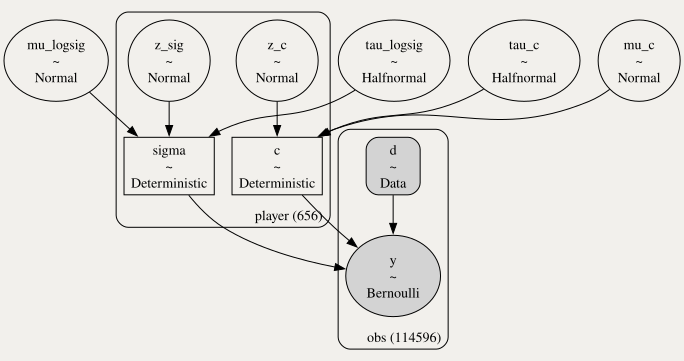

In [10]:
#| echo: false

pm.model_to_graphviz(hitter_sdt, graph_attr={'bgcolor':'#F2F0EC'})

Sampling: [mu_c, mu_logsig, tau_c, tau_logsig, y, z_c, z_sig]


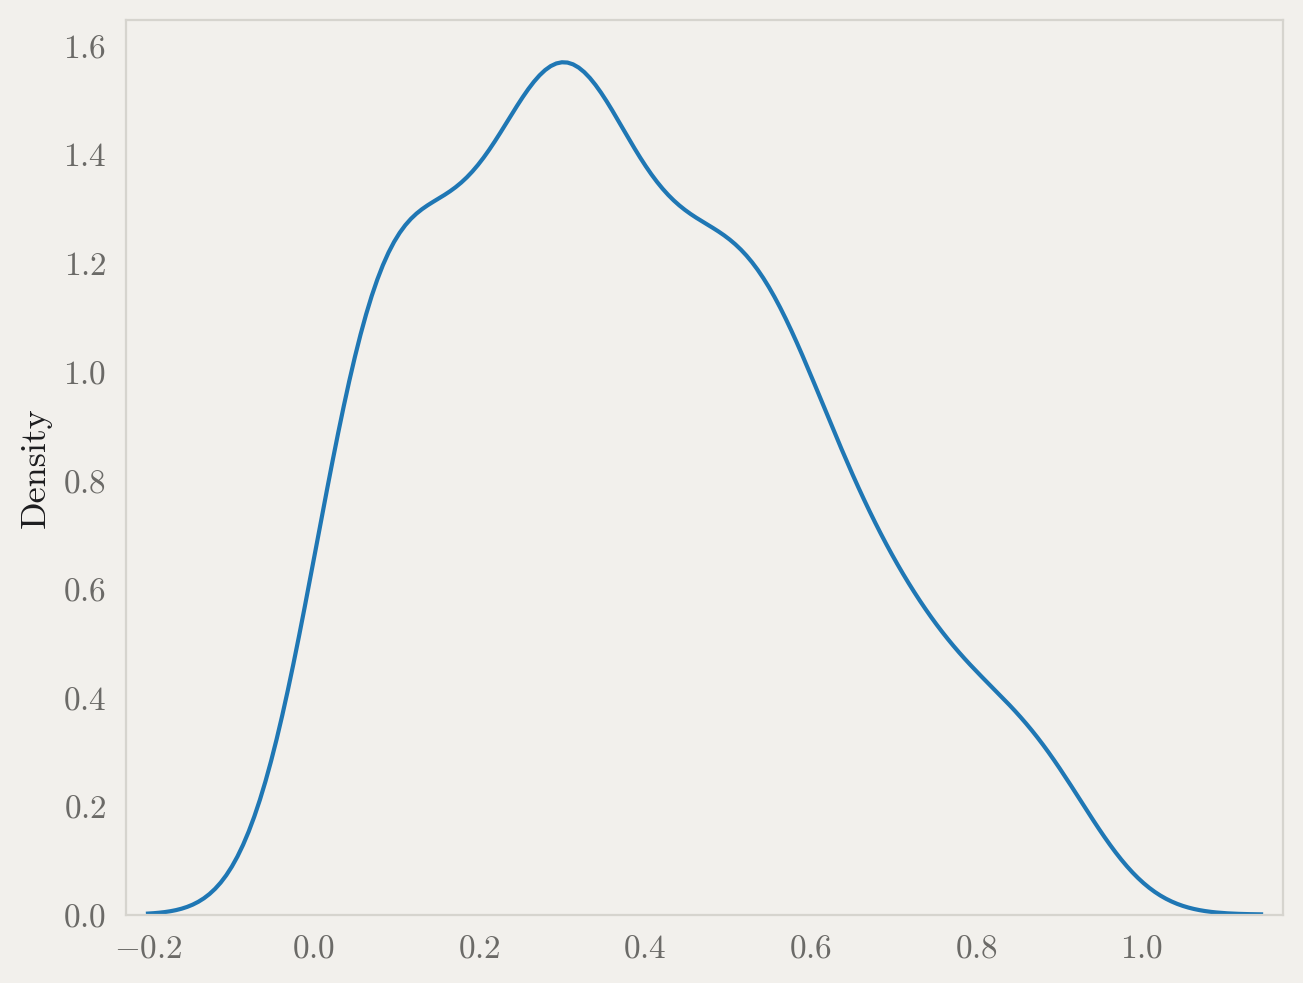

In [11]:
with hitter_sdt:
    prior_pred = pm.sample_prior_predictive(random_seed=random_seed)
    
# mean challenge rate per prior draw
prior_rates = prior_pred.prior_predictive["y"].mean(dim="obs")
sns.kdeplot(prior_rates.values.flatten())
plt.show()

In [12]:
with hitter_sdt:
    trace = pm.sample(random_seed=random_seed)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [mu_c, tau_c, mu_logsig, tau_logsig, z_c, z_sig]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 497 seconds.


In [13]:
az.summary(trace, var_names=['mu_c','tau_c','mu_logsig','tau_logsig'], ci_kind='hdi', ci_prob=0.95)

,mean,sd,hdi95_lb,hdi95_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
mu_c,0.3894,0.0079,0.37,0.41,2330,2415,1.00,0.00017,0.00011
tau_c,0.0874,0.0046,0.078,0.096,1627,2310,1.00,0.00012,8.2e-05
mu_logsig,-1.2297,0.0151,-1.3,-1.2,1974,2067,1.00,0.00034,0.00023
tau_logsig,0.098,0.013,0.072,0.12,550,886,1.00,0.00056,0.0004


### Batter results

Converting the population parameters to inches:

| Parameter | Value | Interpretation |
|---|---|---|
| `mu_c` | 0.389 ft ≈ **4.7 in** | The typical batter doesn't reach a 50% chance of challenging until the pitch is nearly 5 inches beyond the point where the whole ball has cleared the zone. |
| `tau_c` | 0.087 ft ≈ **1.0 in** | Player-to-player SD in criterion. |
| `exp(mu_logsig)` | 0.292 ft ≈ **3.5 in** | Typical perceptual noise. |
| `tau_logsig` | 0.098 | Player-to-player SD of log σ: about ±10%, or ~0.3 in. |

**Criterion varies about three times as much as perception, in the same units:** roughly an inch for c versus about a third of an inch for σ. Batters see the zone about equally well; what separates them is how much evidence they demand before spending a challenge.

The typical criterion is also very conservative. The median missed strike call is only 0.8 in outside the zone, 87% are within 2 in, and fewer than 1% are beyond the typical batter's 4.7 in criterion. Batters only reliably challenge the egregious misses, and the egregious misses are rare.

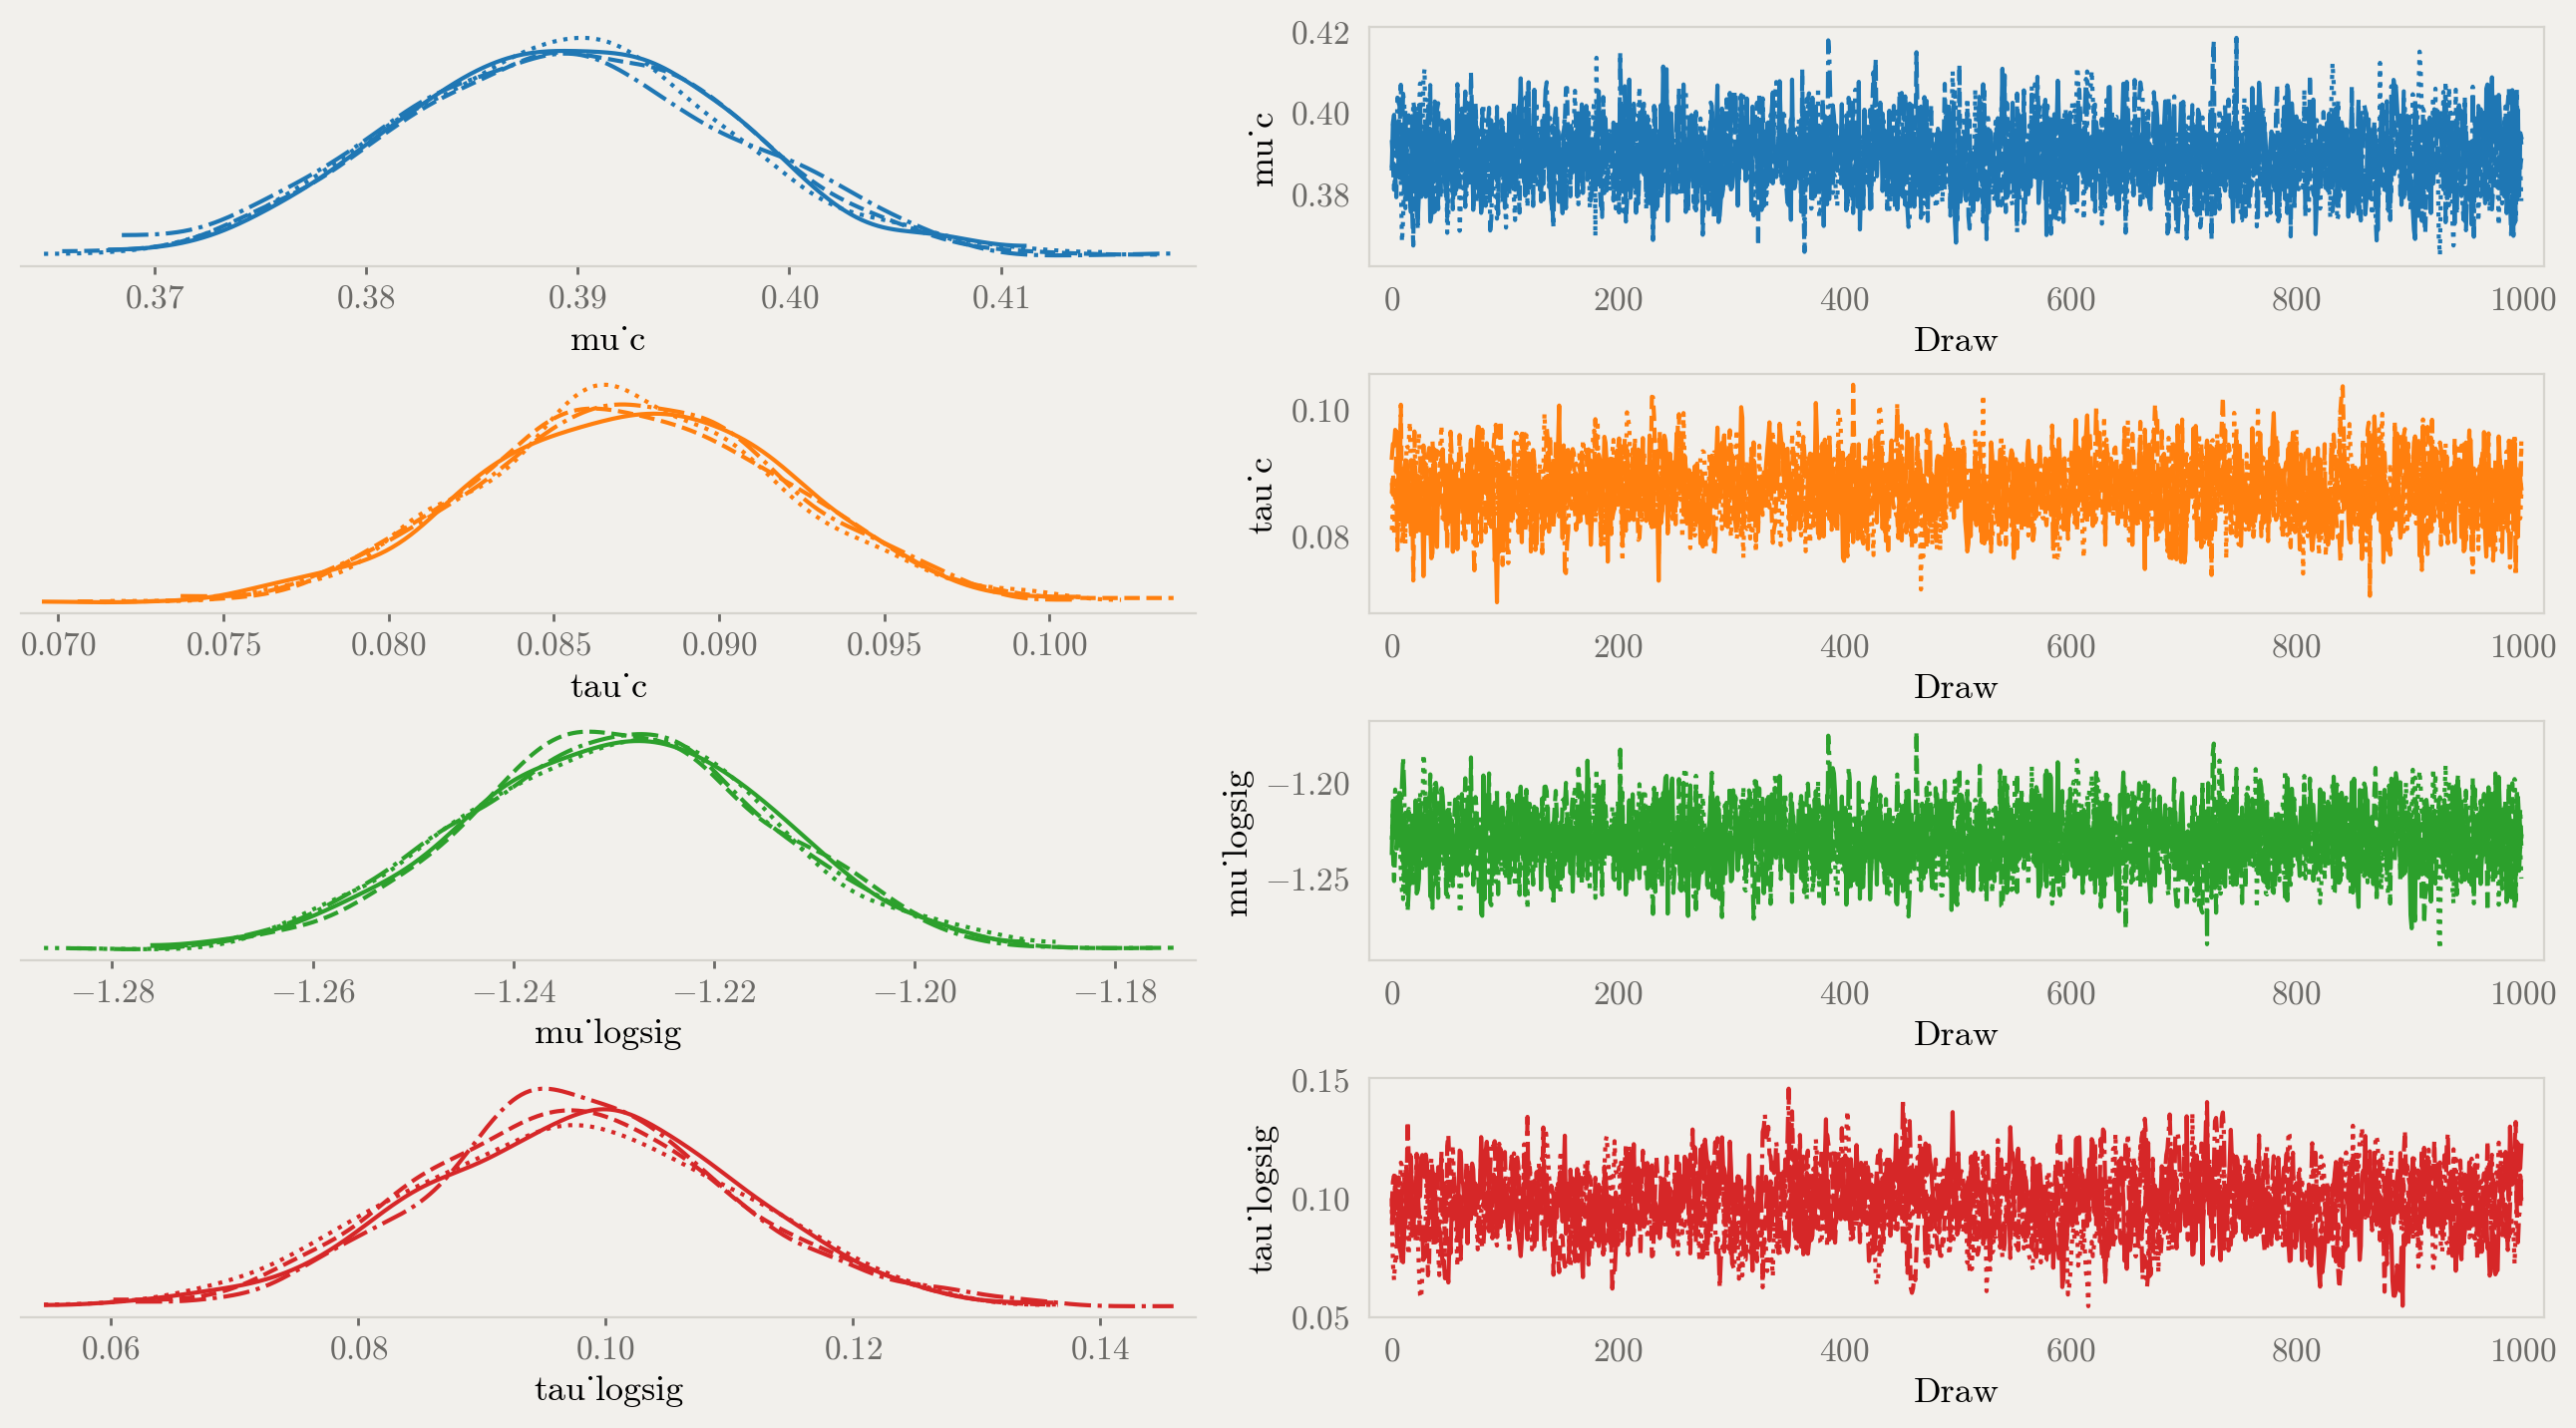

In [14]:
az.plot_trace_dist(trace, var_names=['mu_c','tau_c','mu_logsig','tau_logsig'])
plt.show()

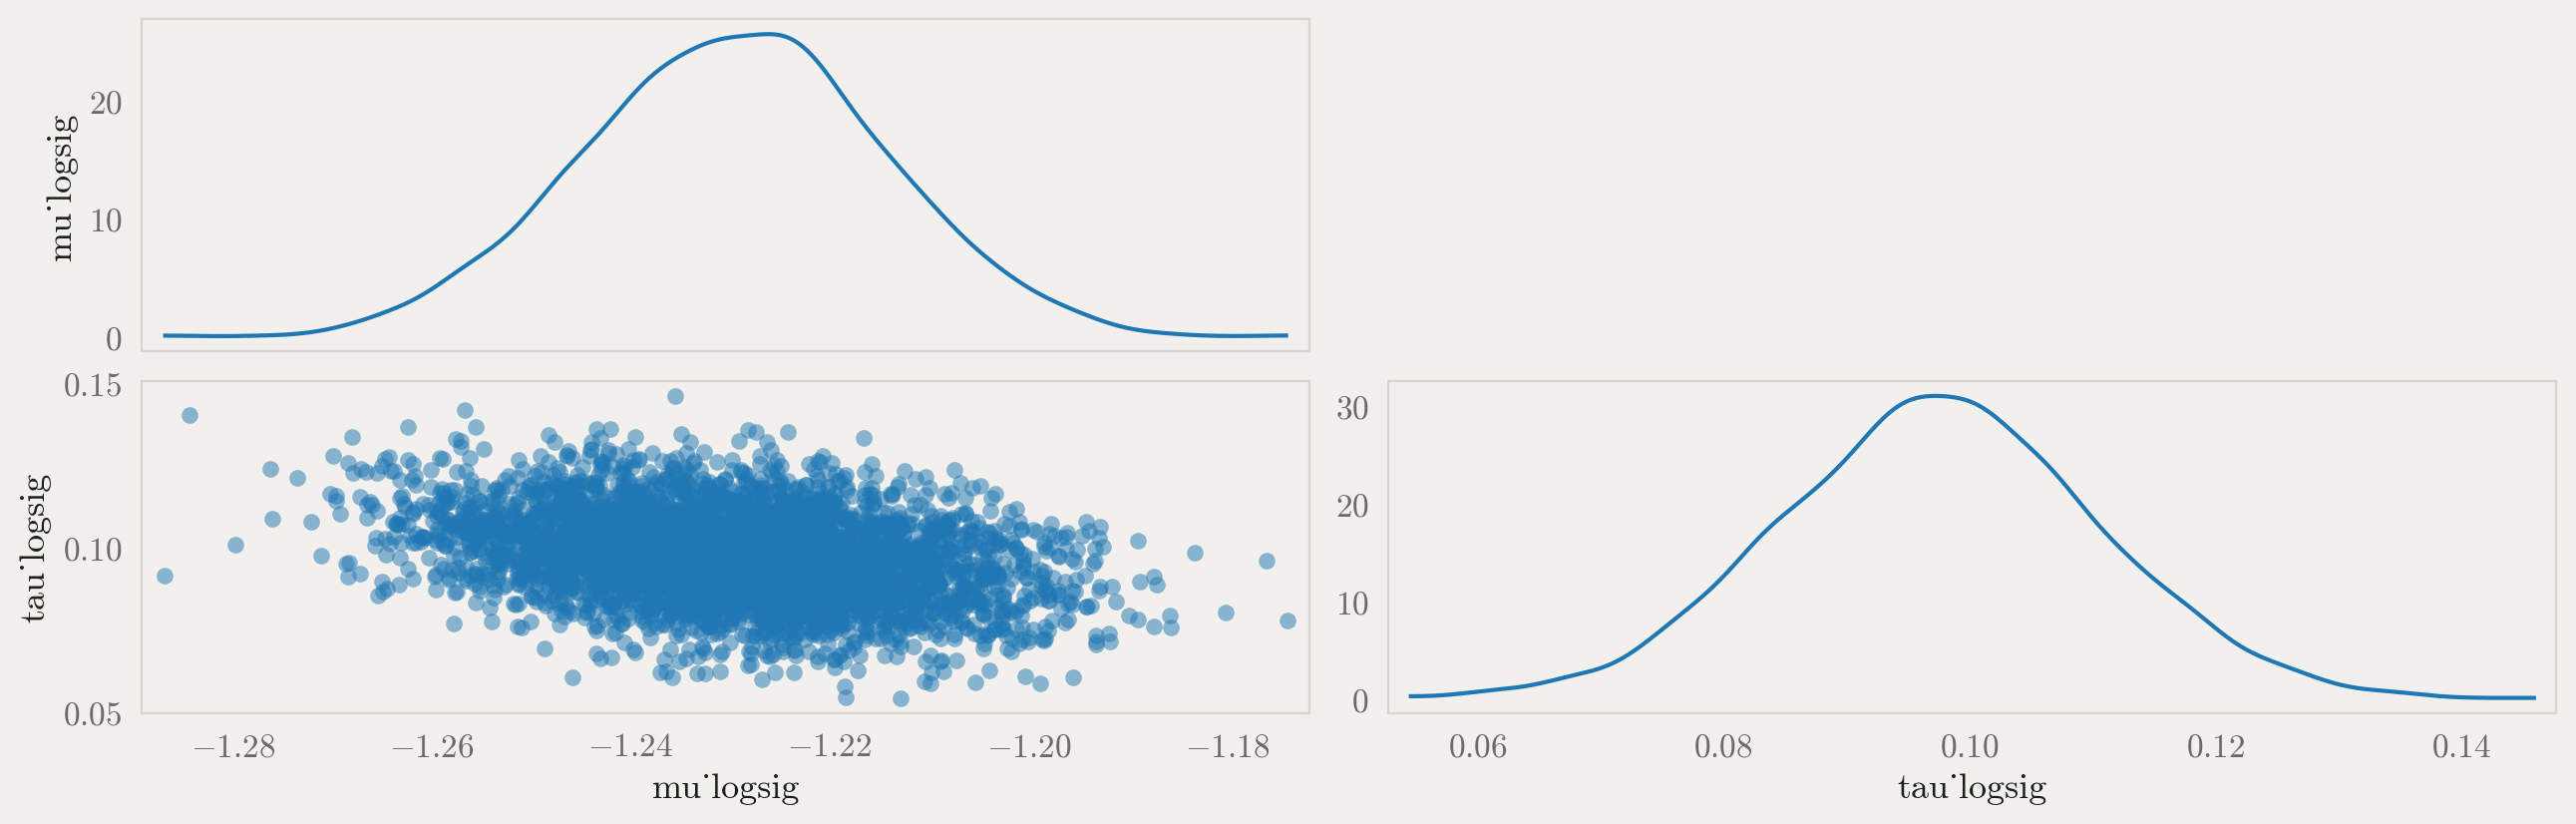

In [15]:
az.plot_pair(trace, var_names=['mu_logsig', 'tau_logsig'])
plt.show()

**Diagnostics.** All four chains mixed well: R-hat = 1.00 for every population parameter, and there were no divergences. `tau_logsig` mixes most slowly (bulk ESS ≈ 550), as expected for a variance parameter near zero. The pair plot of `mu_logsig` against `tau_logsig` shows symmetric marginal densities and no funnel, so the hierarchical structure isn't causing sampling problems.

In [21]:
hitter_summary = build_summary(trace, hitters, 'batter_id', 'batter', 'off_edge_dist')

In [28]:
hitter_summary.sort_values(by='c_mean', ascending=True).head(25).round(3)

,player_name,c_mean,c_ci_lb,c_ci_ub,sigma_mean,sigma_ci_lb,sigma_ci_ub,noise_mean,signal_mean,d_prime
player,,,,,,,,,,
547180,Bryce Harper,0.122,0.053,0.194,0.280,0.229,0.331,-0.318,0.089,1.455
596142,Gary Sánchez,0.154,0.074,0.236,0.294,0.243,0.354,-0.318,0.089,1.385
668901,Mark Vientos,0.189,0.098,0.277,0.299,0.244,0.355,-0.318,0.089,1.361
701398,Sal Stewart,0.192,0.128,0.262,0.270,0.224,0.320,-0.318,0.089,1.506
694249,Cole Carrigg,0.194,0.108,0.278,0.308,0.252,0.362,-0.318,0.089,1.323
694384,Nolan Schanuel,0.196,0.123,0.275,0.283,0.233,0.333,-0.318,0.089,1.437
687282,Gabriel Rincones Jr.,0.215,0.086,0.343,0.301,0.241,0.355,-0.318,0.089,1.354
665923,Esteury Ruiz,0.223,0.127,0.323,0.308,0.249,0.361,-0.318,0.089,1.323
514888,Jose Altuve,0.227,0.151,0.306,0.295,0.241,0.342,-0.318,0.089,1.380


**The 25 batters with the lowest criterion.** Two observations:

- **σ barely moves down the list**, staying around 0.27–0.32 ft, and the individual σ intervals overlap heavily. **c separates players clearly.** Bryce Harper's criterion interval (0.05–0.19 ft) doesn't come close to the league average of 0.39 ft.
- **The model's ranking recovers the outcome leaderboard without using outcomes.** Eight of the ten recall leaders in the baseline table are among the 25 lowest criteria: Harper, Sánchez, Stewart, Schanuel, Carrigg, Ruiz, Bleday and Butler. The model only sees each pitch's location and whether the batter challenged; it never sees whether a challenge succeeded. None of the precision leaders appear on this list, which is the trade-off the baseline section described: a low criterion buys recall at the cost of precision.

**d′** is computed as the league-wide gap between missed calls and correct calls, divided by each player's σ. Every batter faces the same task, so differences in d′ come only from perception, and they're small: about 1.3 to 1.5 in this table. d′ is compared within each position group only. The gap between missed and correct calls is geometrically different for batters and catchers, so their d′ values aren't on the same scale.

The SDT plots below draw each player's noise and signal distributions at the league-wide separation, with their criterion (dashed line) and its 95% HDI (shaded band).

/Users/chrishires/Python/ABS_SDT/.pixi/envs/default/lib/python3.14/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 237 (\N{LATIN SMALL LETTER I WITH ACUTE}) missing from font(s) cmr10.
  fig.canvas.print_figure(bytes_io, **kw)


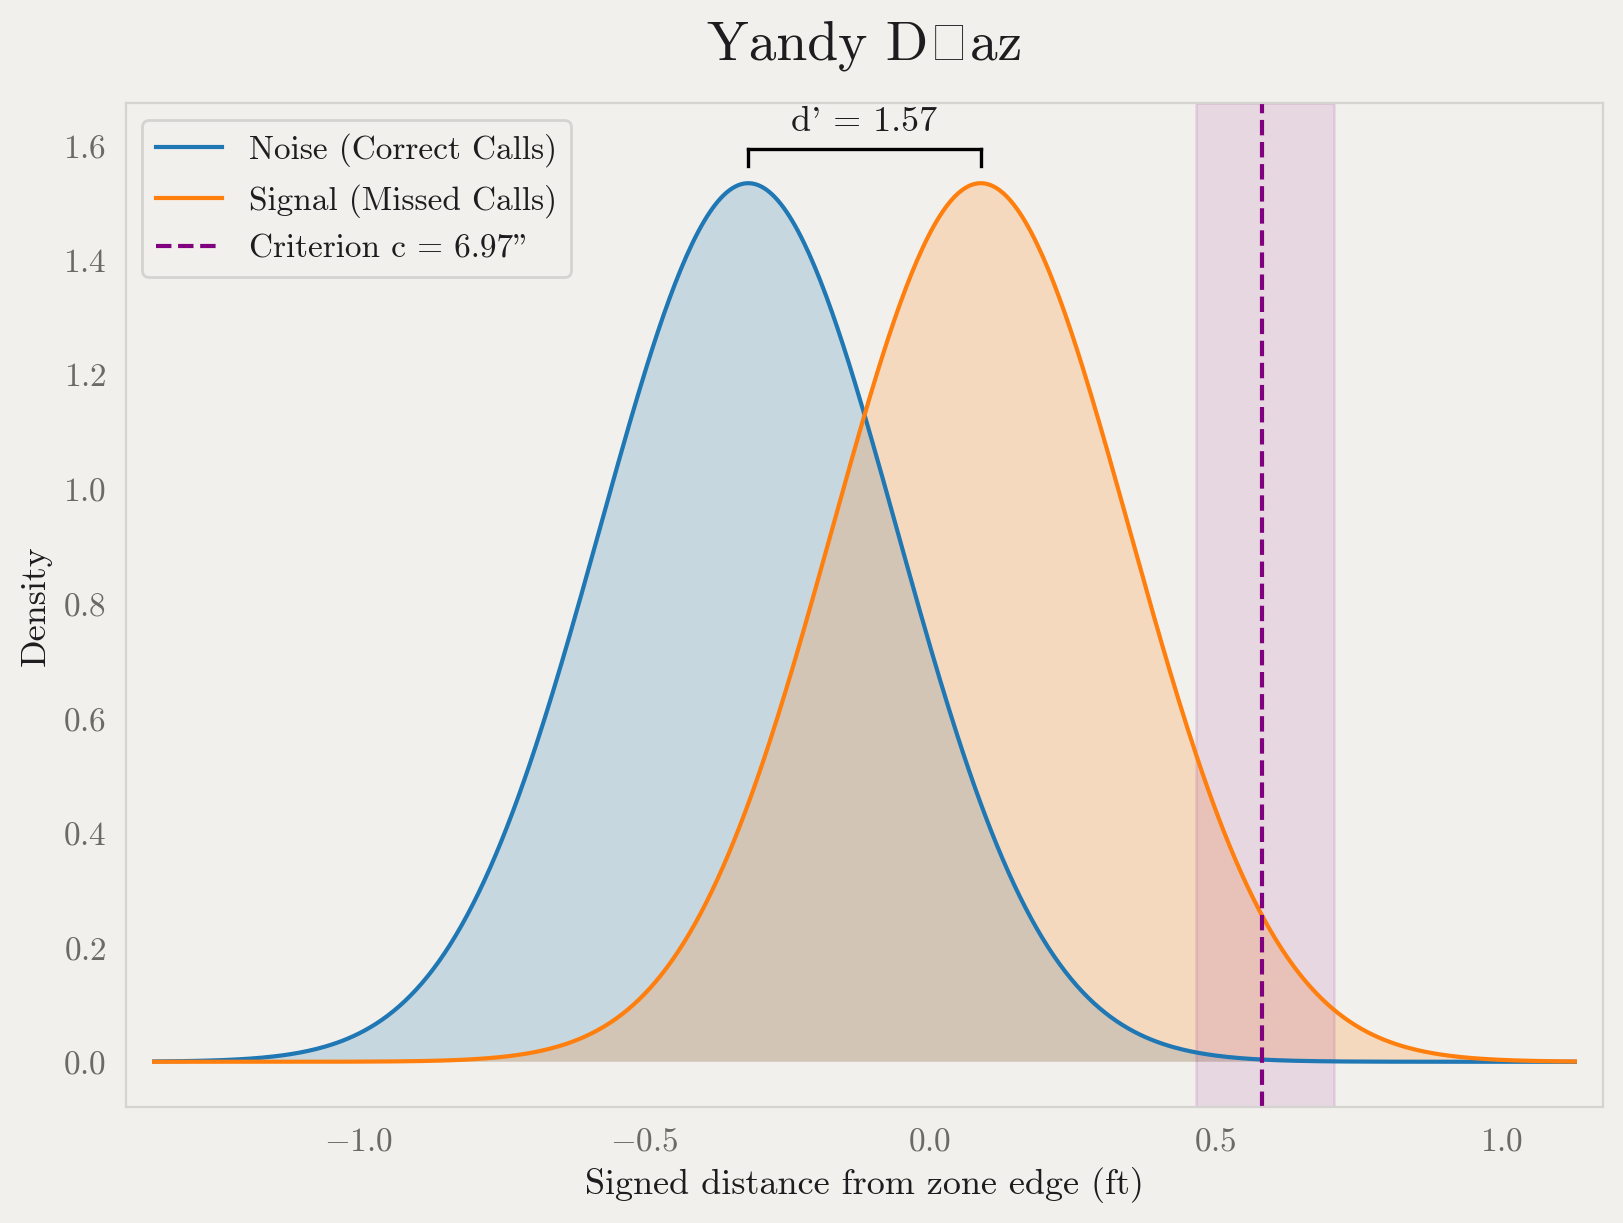

In [30]:
plot_sdt('650490', hitter_summary)

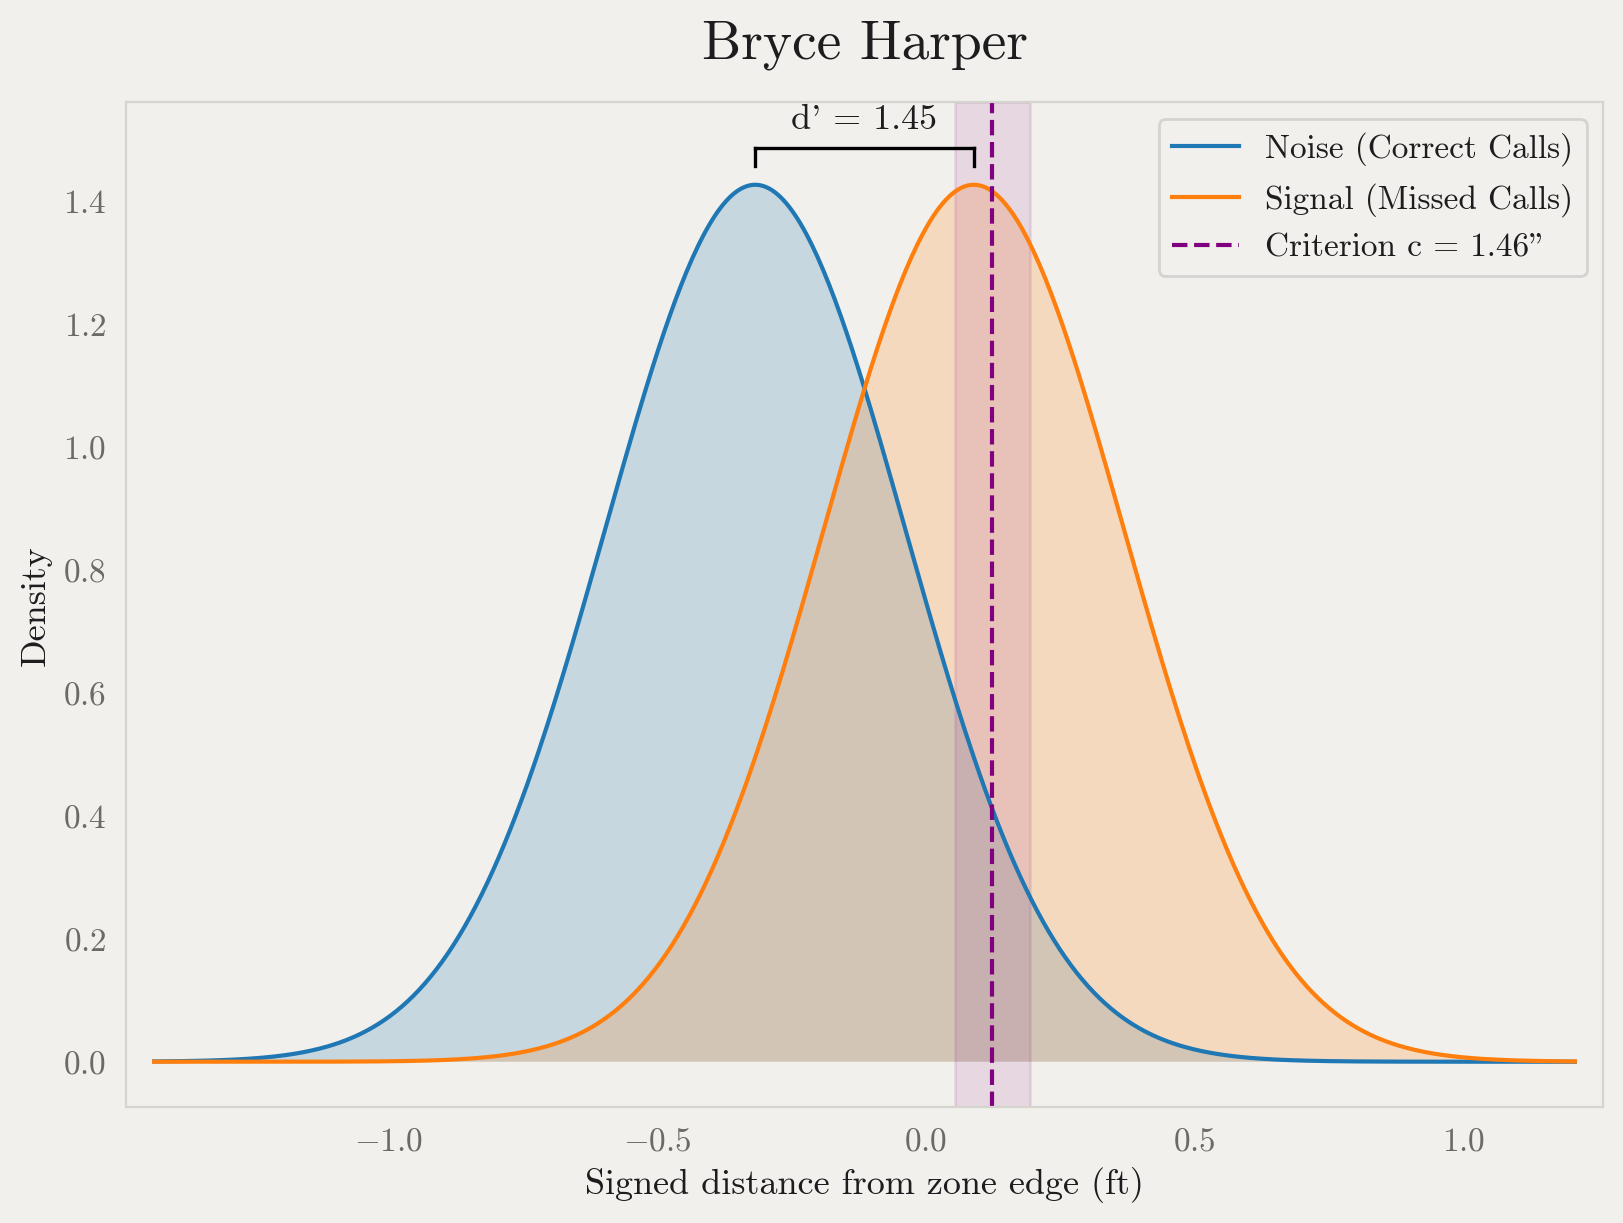

In [31]:
plot_sdt('547180',hitter_summary)

## Pitchers: too sparse to model

Pitchers can challenge too, but they rarely do:

- **179 challenges on 256,734 called balls (0.07%)**, spread across 109 pitchers. Most pitchers challenged once or twice all season.
- **Only 40% were overturned**, the lowest success rate of the three roles.

A fit of this model on partial-season data produced a criterion of more than a foot. That's well beyond the most extreme pitch any pitcher challenged (5.2 in), which means c was absorbing how rare pitcher challenges are rather than locating a threshold. With this few events per player, σ and c aren't identifiable.

The model cells below are kept for reference but weren't run on the full season. The table at the end of this section summarizes pitcher challenges descriptively.

**Consequence for the catcher model:** the catcher is treated as the defense's decision-maker. Pitcher-challenged pitches are dropped from the catcher universe rather than coded as pitches the catcher chose not to challenge, because a non-challenge can't be attributed to one of two possible challengers.

In [41]:
pitchers =  data[data['originalCallCode'].isin(['B','*B'])][['pitcher_id','pitcher','review_player_id','def_edge_dist','TP','FP','TN','Def_FN']]
pitchers['challenge'] = np.where(pitchers['review_player_id'] == pitchers['pitcher_id'],1,0)
pitchers.head()

,pitcher_id,pitcher,review_player_id,def_edge_dist,TP,FP,TN,Def_FN,challenge
2,657277,Logan Webb,NaN,-0.651511,False,False,True,False,0
7,657277,Logan Webb,NaN,-1.767125,False,False,True,False,0
8,657277,Logan Webb,NaN,0.061610,False,False,False,True,0
9,657277,Logan Webb,NaN,-0.163904,False,False,True,False,0
13,657277,Logan Webb,NaN,-0.594258,False,False,True,False,0


In [43]:
pitchers['challenge'].sum()

np.int64(179)

In [44]:
pitchers['challenge'].sum() / len(pitchers)

np.float64(0.0006972196904188771)

In [33]:
# Data Prep

pitcher_ids = pitchers['pitcher_id'].astype('category')
n_players = len(pitcher_ids.cat.categories)
n_pitches = len(pitchers)
obs_ids = np.arange(n_pitches)
pitcher_idx = pitcher_ids.cat.codes.to_numpy().astype('int64')
distance = pitchers['def_edge_dist'].to_numpy()
challenge = pitchers['challenge'].to_numpy()

In [34]:
with pm.Model(coords={'player': pitcher_ids.cat.categories.astype('str'), 'obs': obs_ids}) as pitcher_sdt:
    
    #hypers
    mu_c = pm.Normal('mu_c', 0, 0.5)
    tau_c = pm.HalfNormal('tau_c', 0.5)
    mu_logsig = pm.Normal('mu_logsig', -0.7, 0.5)
    tau_logsig = pm.HalfNormal('tau_logsig', 0.5)

    # player offsets
    z_c = pm.Normal('z_c', 0, 1, dims='player')
    z_sig = pm.Normal('z_sig', 0, 1, dims='player')

    d = pm.Data('d', distance, dims='obs')
    c = pm.Deterministic('c', mu_c + z_c * tau_c, dims='player')
    sigma = pm.Deterministic('sigma', pm.math.exp(mu_logsig + z_sig * tau_logsig), dims='player')

    # Likelihood
    eta = ((d - c[pitcher_idx]) / sigma[pitcher_idx])
    p = pm.math.invprobit(eta)
    pm.Bernoulli('y', p=p, observed=challenge, dims='obs')



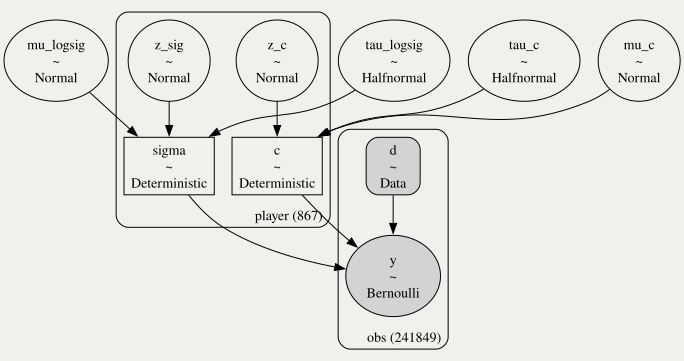

In [35]:
pm.model_to_graphviz(pitcher_sdt, graph_attr={'bgcolor':'#F2F0EC'})

In [ ]:
with pitcher_sdt:
    prior_pred = pm.sample_prior_predictive(random_seed=random_seed)
    
# mean challenge rate per prior draw
prior_rates = prior_pred.prior_predictive["y"].mean(dim="obs")
sns.kdeplot(prior_rates.values.flatten())
plt.show()

In [ ]:
with pitcher_sdt:
    pitcher_trace = pm.sample(random_seed=random_seed, target_accept=0.95)

In [ ]:
az.summary(pitcher_trace, var_names=['mu_c','tau_c','mu_logsig','tau_logsig'], ci_kind='hdi', ci_prob=0.95)

In [ ]:
az.plot_trace_dist(pitcher_trace, var_names=['mu_c','tau_c','mu_logsig','tau_logsig'])

In [ ]:
az.plot_pair(pitcher_trace, var_names=['mu_logsig', 'tau_logsig'])

In [ ]:
pitcher_summary = build_summary(pitcher_trace, pitchers, 'pitcher_id','pitcher','def_edge_dist')

In [ ]:
pitcher_summary.head(25)

In [ ]:
plot_sdt('543243',pitcher_summary)

In [38]:
pitcher_challenges = pitchers[(pitchers['challenge'] == True)].groupby(by=['pitcher_id','pitcher','review_player_id']).agg({
    'def_edge_dist':'mean',
    'TP': 'sum',
    'FP': 'sum',
    'TN': 'sum',
    'Def_FN': 'sum', 
    'challenge':'sum'})
pitcher_challenges

,,,def_edge_dist,TP,FP,TN,Def_FN,challenge
pitcher_id,pitcher,review_player_id,,,,,,
500779,Jose Quintana,500779.0,-0.204892,0,1,0,0,1
518585,Fernando Cruz,518585.0,-0.024108,0,1,0,0,1
527048,Martín Pérez,527048.0,-0.058180,0,2,0,0,2
543135,Nathan Eovaldi,543135.0,0.047597,1,0,0,0,1
543243,Sonny Gray,543243.0,-0.028498,1,1,0,0,2
...,...,...,...,...,...,...,...,...
700712,Walbert Ureña,700712.0,-0.112319,0,1,0,0,1
701542,Will Warren,701542.0,-0.124171,0,1,0,0,1
702070,Noah Cameron,702070.0,-0.009060,0,1,0,0,1


## Catchers

This is the same model, fit to pitches originally called balls, with `def_edge_dist` as the evidence (positive means the pitch was inside the zone). 111 catchers made 5,612 challenges, and 58.6% were overturned, compared with 48.9% for batters.

In [46]:
catchers =  data[data['originalCallCode'].isin(['B','*B'])][['catcher_id','catcher','pitcher_id','pitcher','review_player_id','def_edge_dist','TP','FP','TN','Def_FN']]
catchers['p_challenge'] = catchers['review_player_id'] == catchers['pitcher_id']
catchers = catchers[catchers['p_challenge'] == False] # Drop the pitcher challenges
catchers['challenge'] = np.where(catchers['review_player_id'] == catchers['catcher_id'],1,0)

keep_cols = ['catcher_id','catcher','review_player_id','def_edge_dist','TP','FP','TN','Def_FN','challenge']
catchers = catchers[keep_cols]

catchers

,catcher_id,catcher,review_player_id,def_edge_dist,TP,FP,TN,Def_FN,challenge
2,672275,Patrick Bailey,NaN,-0.651511,False,False,True,False,0
7,672275,Patrick Bailey,NaN,-1.767125,False,False,True,False,0
8,672275,Patrick Bailey,NaN,0.061610,False,False,False,True,0
9,672275,Patrick Bailey,NaN,-0.163904,False,False,True,False,0
13,672275,Patrick Bailey,NaN,-0.594258,False,False,True,False,0
...,...,...,...,...,...,...,...,...,...
714010,596142,Gary Sánchez,NaN,-0.185515,False,False,True,False,0
714011,596142,Gary Sánchez,NaN,-0.525034,False,False,True,False,0
714012,596142,Gary Sánchez,NaN,-0.274689,False,False,True,False,0
714017,596142,Gary Sánchez,NaN,-1.941392,False,False,True,False,0


In [47]:
# Data Prep

catcher_ids = catchers['catcher_id'].astype('category')
n_players = len(catcher_ids.cat.categories)
n_pitches = len(catchers)
obs_ids = np.arange(n_pitches)
catcher_idx = catcher_ids.cat.codes.to_numpy().astype('int64')
distance = catchers['def_edge_dist'].to_numpy()
challenge = catchers['challenge'].to_numpy()

In [48]:
with pm.Model(coords={'player': catcher_ids.cat.categories.astype('str'), 'obs': obs_ids}) as catcher_sdt:
    
    #hypers
    mu_c = pm.Normal('mu_c', 0, 0.5)
    tau_c = pm.HalfNormal('tau_c', 0.5)
    mu_logsig = pm.Normal('mu_logsig', -0.7, 0.5)
    tau_logsig = pm.HalfNormal('tau_logsig', 0.5)

    # player offsets
    z_c = pm.Normal('z_c', 0, 1, dims='player')
    z_sig = pm.Normal('z_sig', 0, 1, dims='player')

    d = pm.Data('d', distance, dims='obs')
    c = pm.Deterministic('c', mu_c + z_c * tau_c, dims='player')
    sigma = pm.Deterministic('sigma', pm.math.exp(mu_logsig + z_sig * tau_logsig), dims='player')

    # Likelihood
    eta = ((d - c[catcher_idx]) / sigma[catcher_idx])
    p = pm.math.invprobit(eta)
    pm.Bernoulli('y', p=p, observed=challenge, dims='obs')



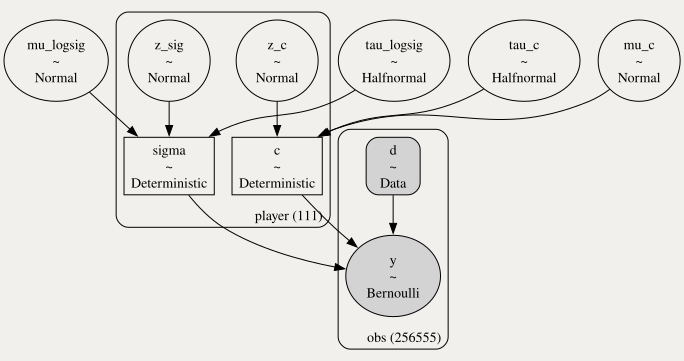

In [49]:
pm.model_to_graphviz(catcher_sdt, graph_attr={'bgcolor':'#F2F0EC'})

Sampling: [mu_c, mu_logsig, tau_c, tau_logsig, y, z_c, z_sig]


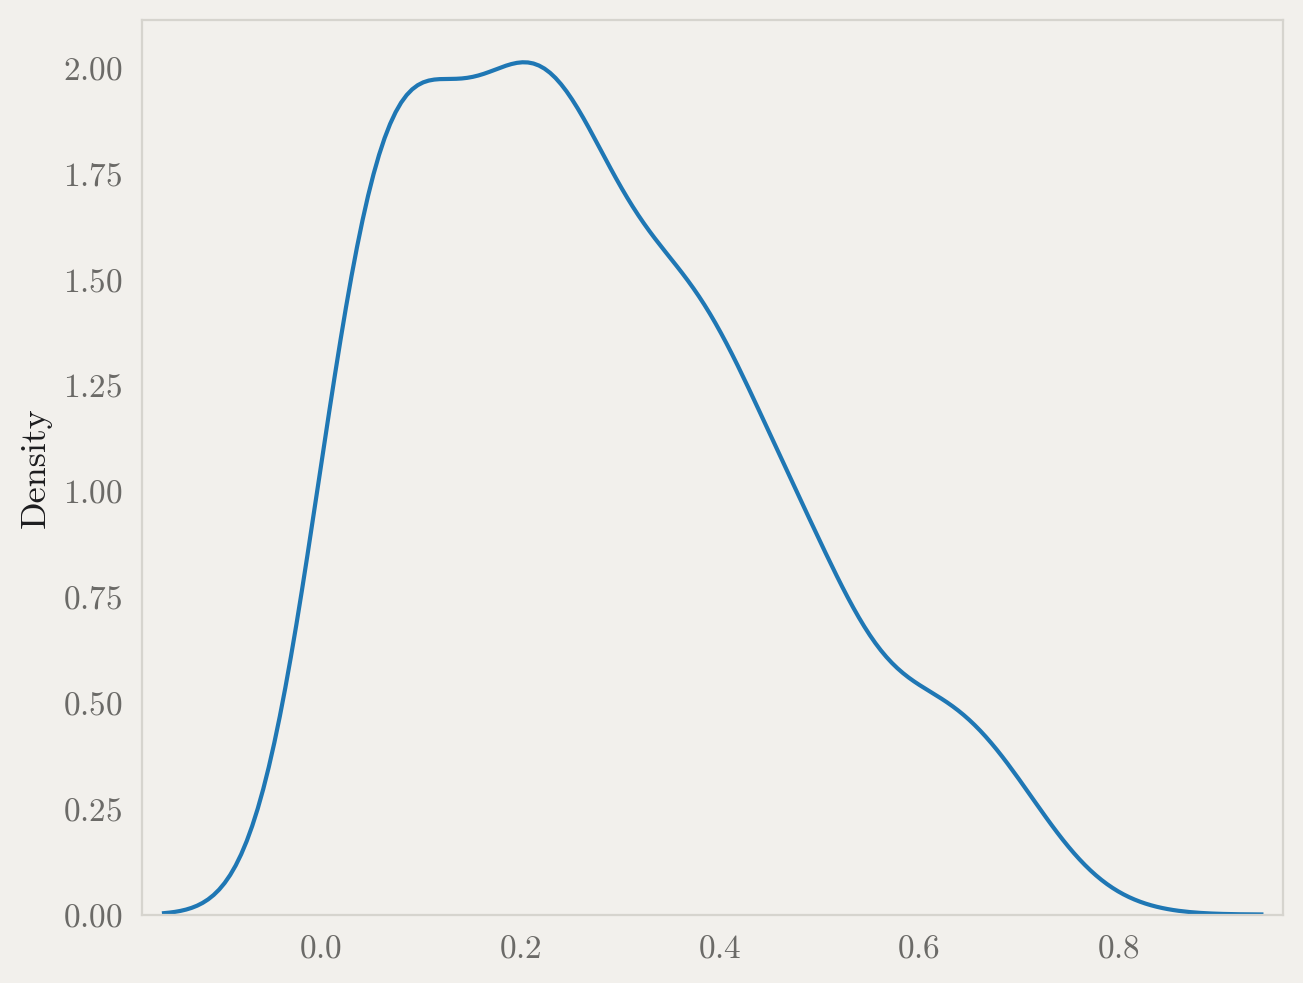

In [50]:
with catcher_sdt:
    prior_pred = pm.sample_prior_predictive(random_seed=random_seed)
    
# mean challenge rate per prior draw
prior_rates = prior_pred.prior_predictive["y"].mean(dim="obs")
sns.kdeplot(prior_rates.values.flatten())
plt.show()

In [51]:
with catcher_sdt:
    catcher_trace = pm.sample(random_seed=random_seed)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [mu_c, tau_c, mu_logsig, tau_logsig, z_c, z_sig]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 976 seconds.


In [52]:
az.summary(catcher_trace, var_names=['mu_c','tau_c','mu_logsig','tau_logsig'], ci_kind='hdi', ci_prob=0.95)

,mean,sd,hdi95_lb,hdi95_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
mu_c,0.181,0.0042,0.17,0.19,2384,2371,1.00,8.6e-05,6e-05
tau_c,0.0279,0.0033,0.022,0.035,1487,2225,1.00,8.6e-05,7.2e-05
mu_logsig,-1.7776,0.0142,-1.8,-1.7,2999,2588,1.00,0.00026,0.00018
tau_logsig,0.0837,0.0134,0.058,0.11,1207,1615,1.00,0.00038,0.00028


### Catcher results

| Parameter | Value | Interpretation |
|---|---|---|
| `mu_c` | 0.181 ft ≈ **2.2 in** | Typical criterion: much more aggressive than batters. |
| `tau_c` | 0.028 ft ≈ **0.3 in** | Player-to-player SD in criterion. |
| `exp(mu_logsig)` | 0.169 ft ≈ **2.0 in** | Typical perceptual noise: sharper than batters. |
| `tau_logsig` | 0.084 | Player-to-player SD of log σ: about ±8%, or ~0.2 in. |

**The same pattern holds within catchers:** criterion varies about twice as much as perception (0.3 in vs. 0.2 in). Catchers are a more homogeneous group than batters on both dimensions, which makes sense for 111 specialists at one position compared with 656 batters of every type.

Catchers are both more aggressive and more perceptive than batters. Both comparisons are in physical units, so they hold up across groups, and together they explain the gap in success rates. Catchers also challenge a larger share of missed calls (29% vs. 18%). Even so, the median missed ball call is only 0.7 in inside the zone, and just 8% are beyond the typical catcher's criterion.

**Diagnostics.** The fit was clean: R-hat = 1.00 for every population parameter, bulk ESS above 1,200 for each, and no divergences.

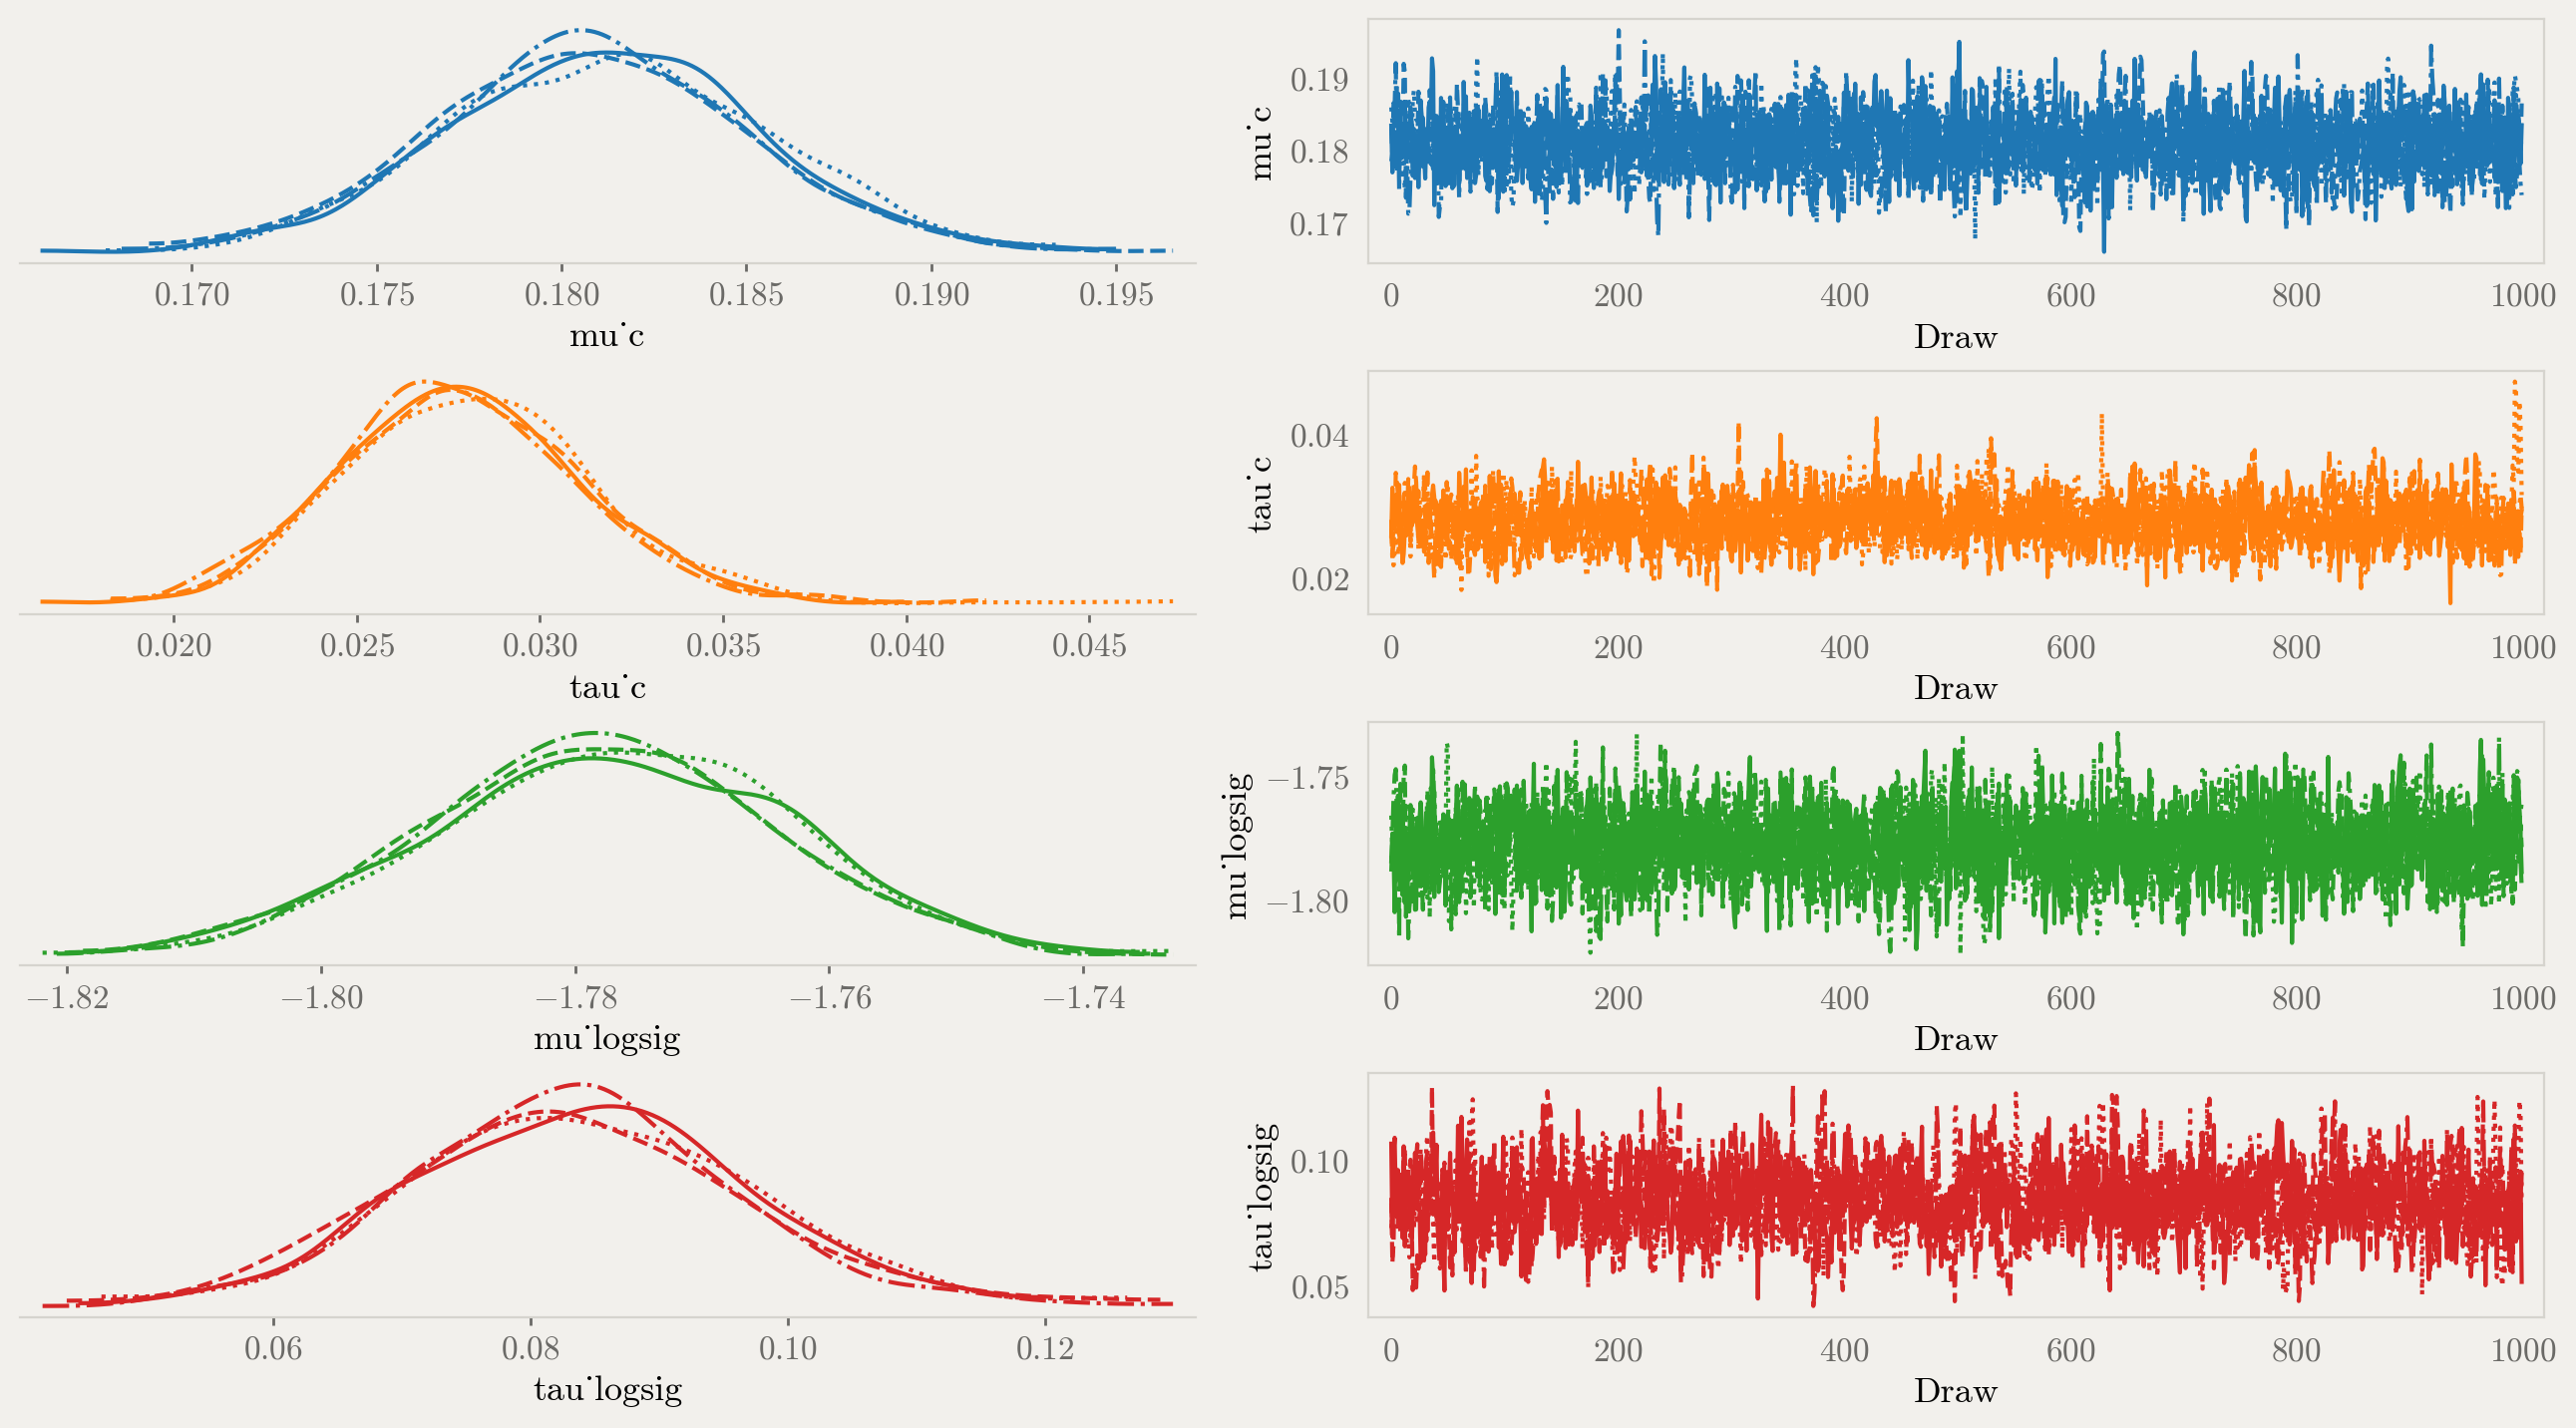

In [53]:
az.plot_trace_dist(catcher_trace, var_names=['mu_c','tau_c','mu_logsig','tau_logsig'])

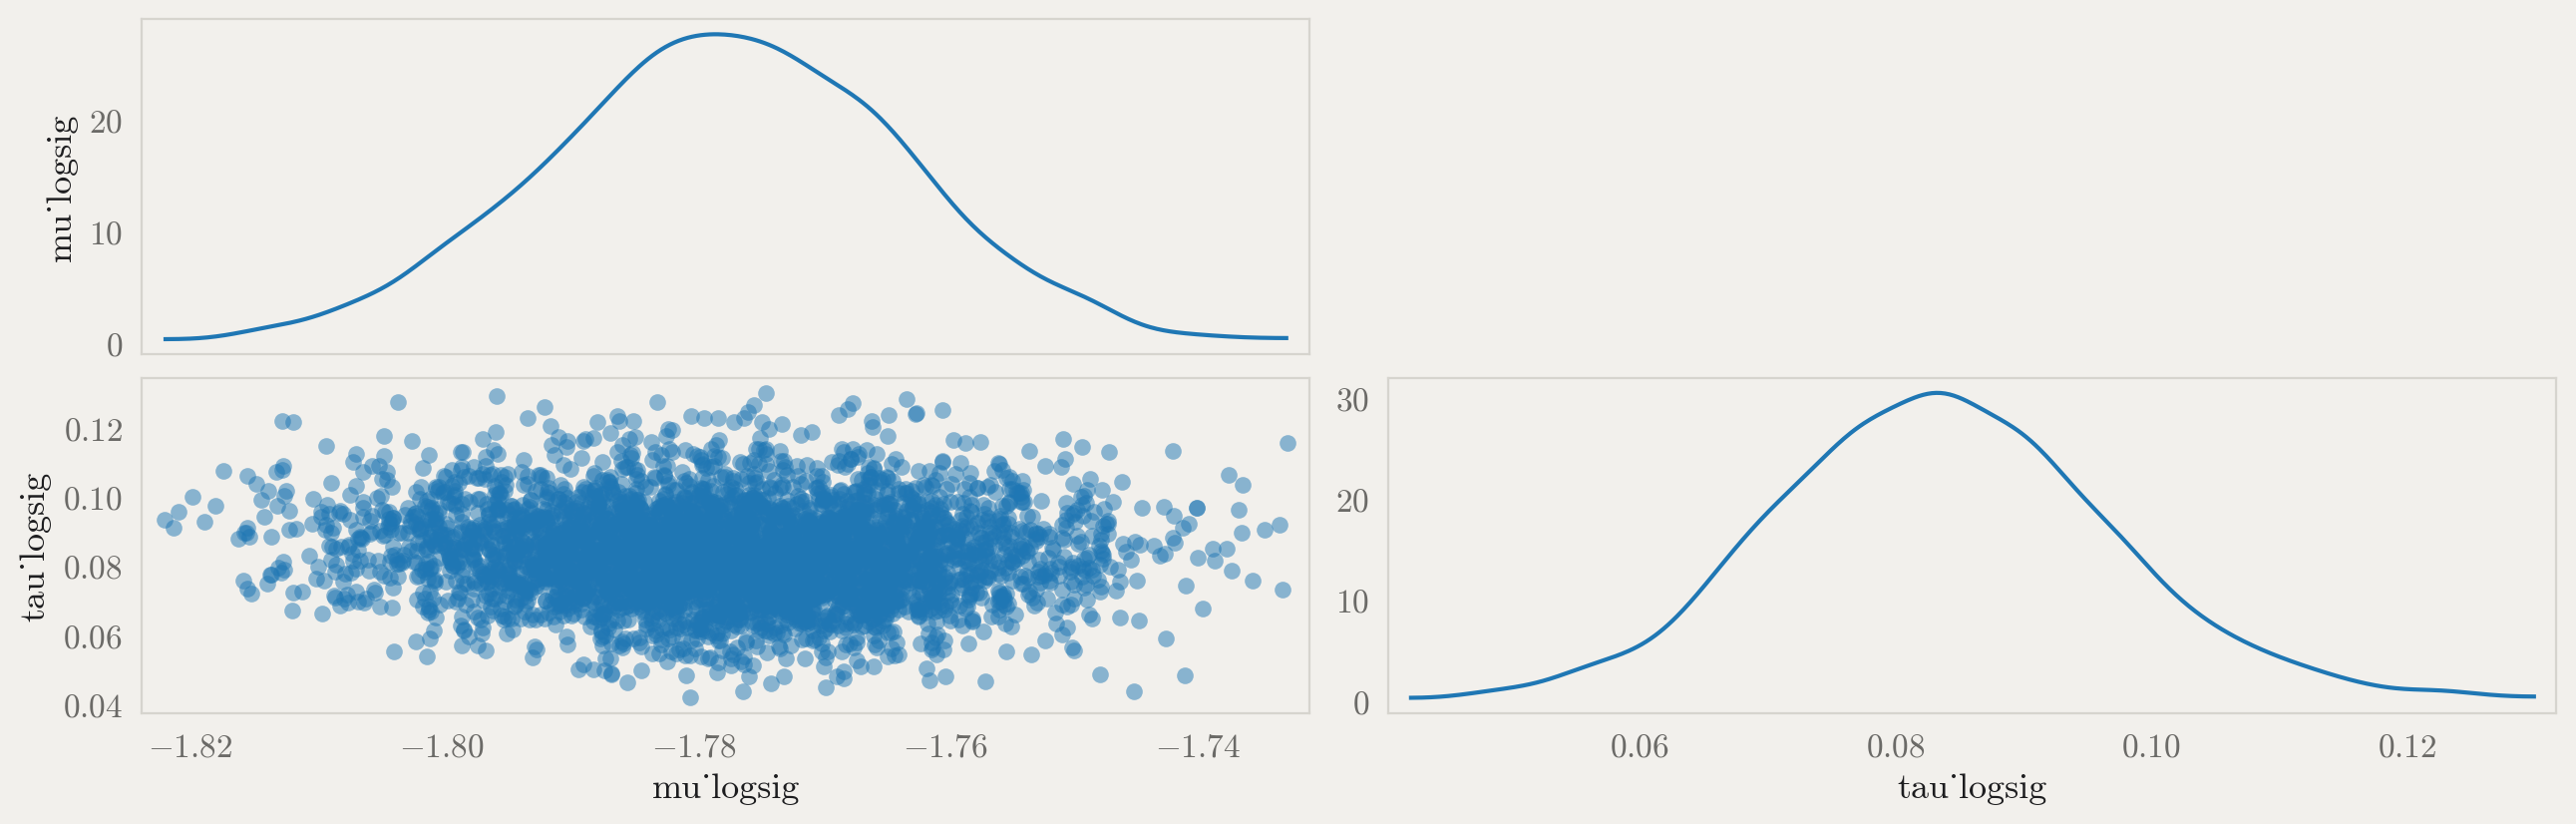

In [54]:
az.plot_pair(catcher_trace, var_names=['mu_logsig', 'tau_logsig'])

In [59]:
catcher_summary = build_summary(catcher_trace, catchers, 'catcher_id','catcher','def_edge_dist')
catcher_summary.sort_values(by='c_mean', ascending=True).head(20).round(3)

,player_name,c_mean,c_ci_lb,c_ci_ub,sigma_mean,sigma_ci_lb,sigma_ci_ub,noise_mean,signal_mean,d_prime
player,,,,,,,,,,
605170,Victor Caratini,0.124,0.102,0.150,0.156,0.139,0.173,-0.676,0.077,4.841
669221,Sean Murphy,0.137,0.103,0.171,0.164,0.141,0.186,-0.676,0.077,4.605
691788,Joe Mack,0.141,0.115,0.167,0.156,0.139,0.175,-0.676,0.077,4.823
691019,Kyle Teel,0.141,0.107,0.174,0.179,0.156,0.200,-0.676,0.077,4.201
672275,Patrick Bailey,0.147,0.119,0.170,0.167,0.150,0.185,-0.676,0.077,4.504
645305,Ali Sánchez,0.147,0.109,0.183,0.183,0.161,0.208,-0.676,0.077,4.122
699024,Leo Bernal,0.148,0.107,0.187,0.175,0.150,0.199,-0.676,0.077,4.309
691011,Drew Romo,0.149,0.118,0.178,0.178,0.157,0.197,-0.676,0.077,4.229
682663,Agustín Ramírez,0.149,0.116,0.184,0.169,0.147,0.193,-0.676,0.077,4.448


**The 20 catchers with the lowest criterion.** Victor Caratini is the most aggressive, at 0.124 ft (1.5 in). Criterion intervals are much narrower than batters', because catchers see many more pitches each: every called ball while they're behind the plate, not just their own plate appearances. σ again sits in a narrow band (about 0.16–0.19 ft) with overlapping intervals. d′ is computed at the catchers' own league-wide separation, so these values are comparable only to other catchers, not to the batter table.

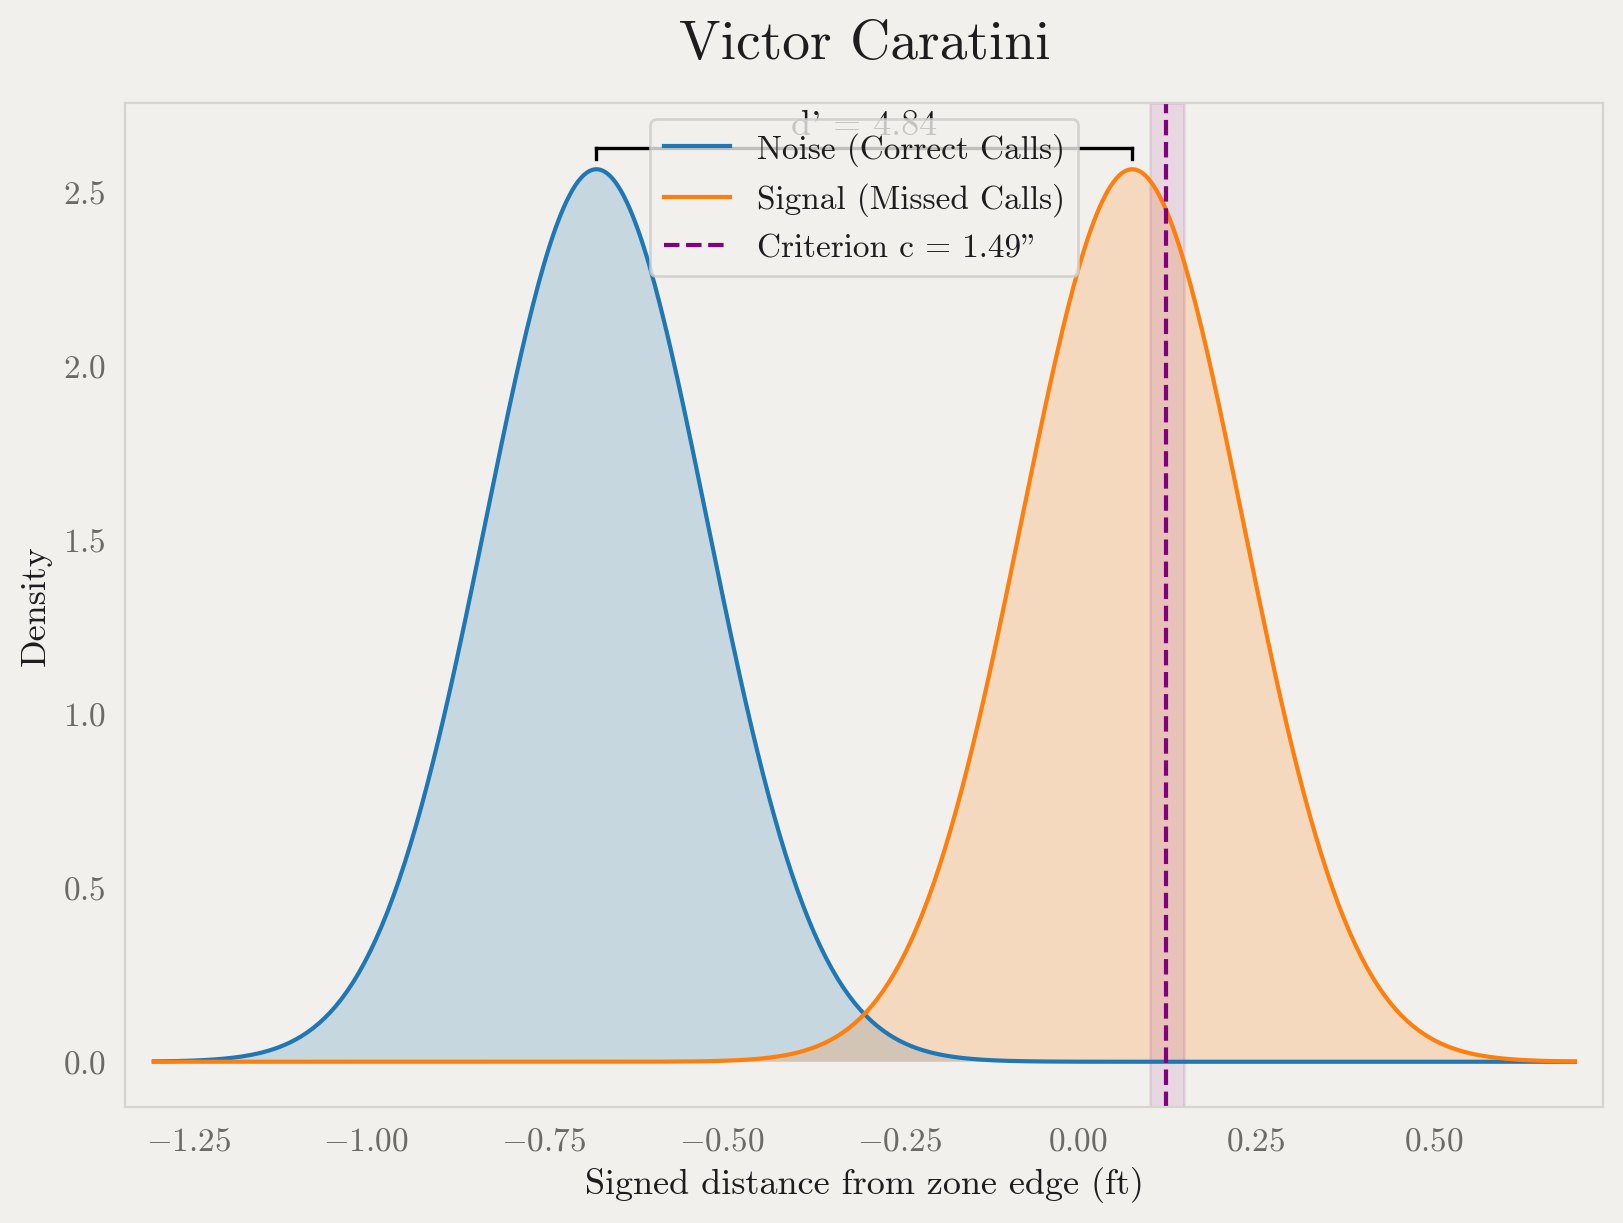

In [56]:
plot_sdt('605170',catcher_summary)

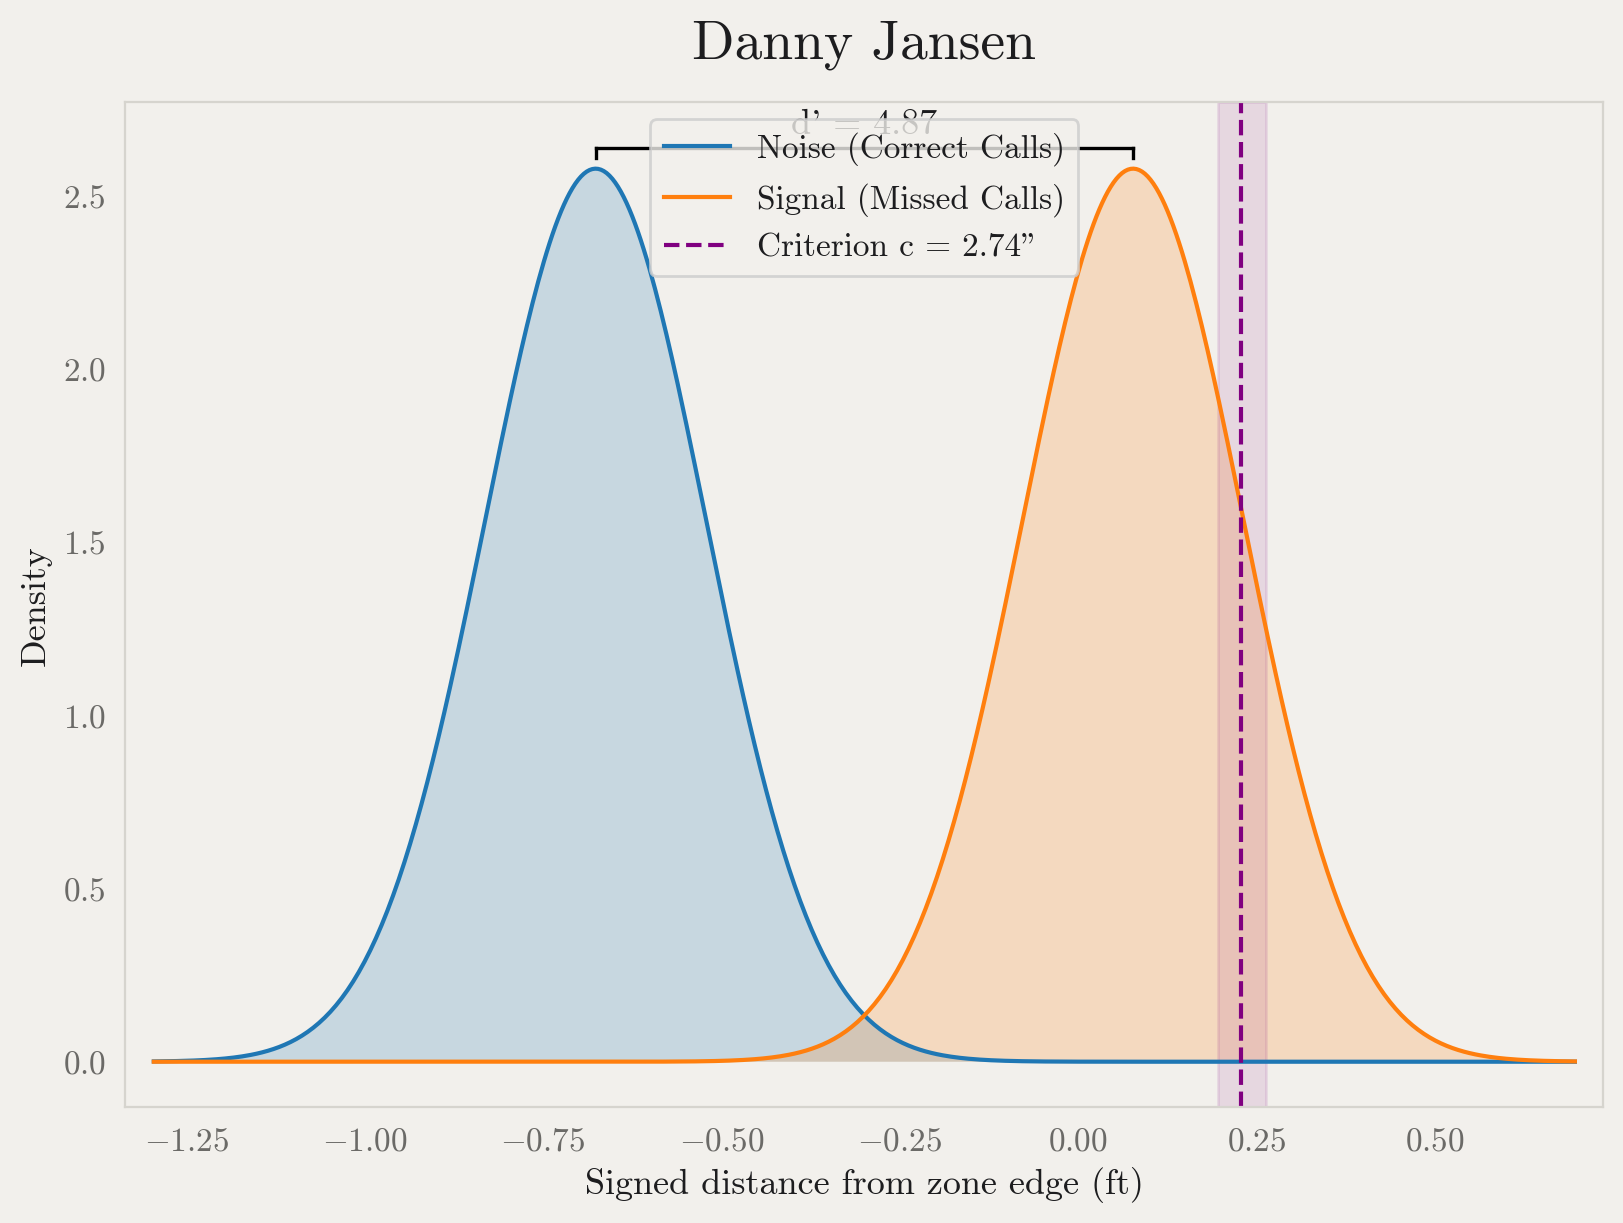

In [58]:
plot_sdt('643376',catcher_summary)

### One player, two roles

William Contreras appears in both models, as a catcher and as a batter. Comparing his two σ values in inches is a within-person comparison: the same eyes, from a different vantage point and with a different task. (His two d′ values aren't comparable, for the same reason batter and catcher d′ aren't.) If his σ as a catcher is clearly smaller than his σ as a batter, the catcher/batter perception gap is at least partly about the position, not just about who plays catcher.

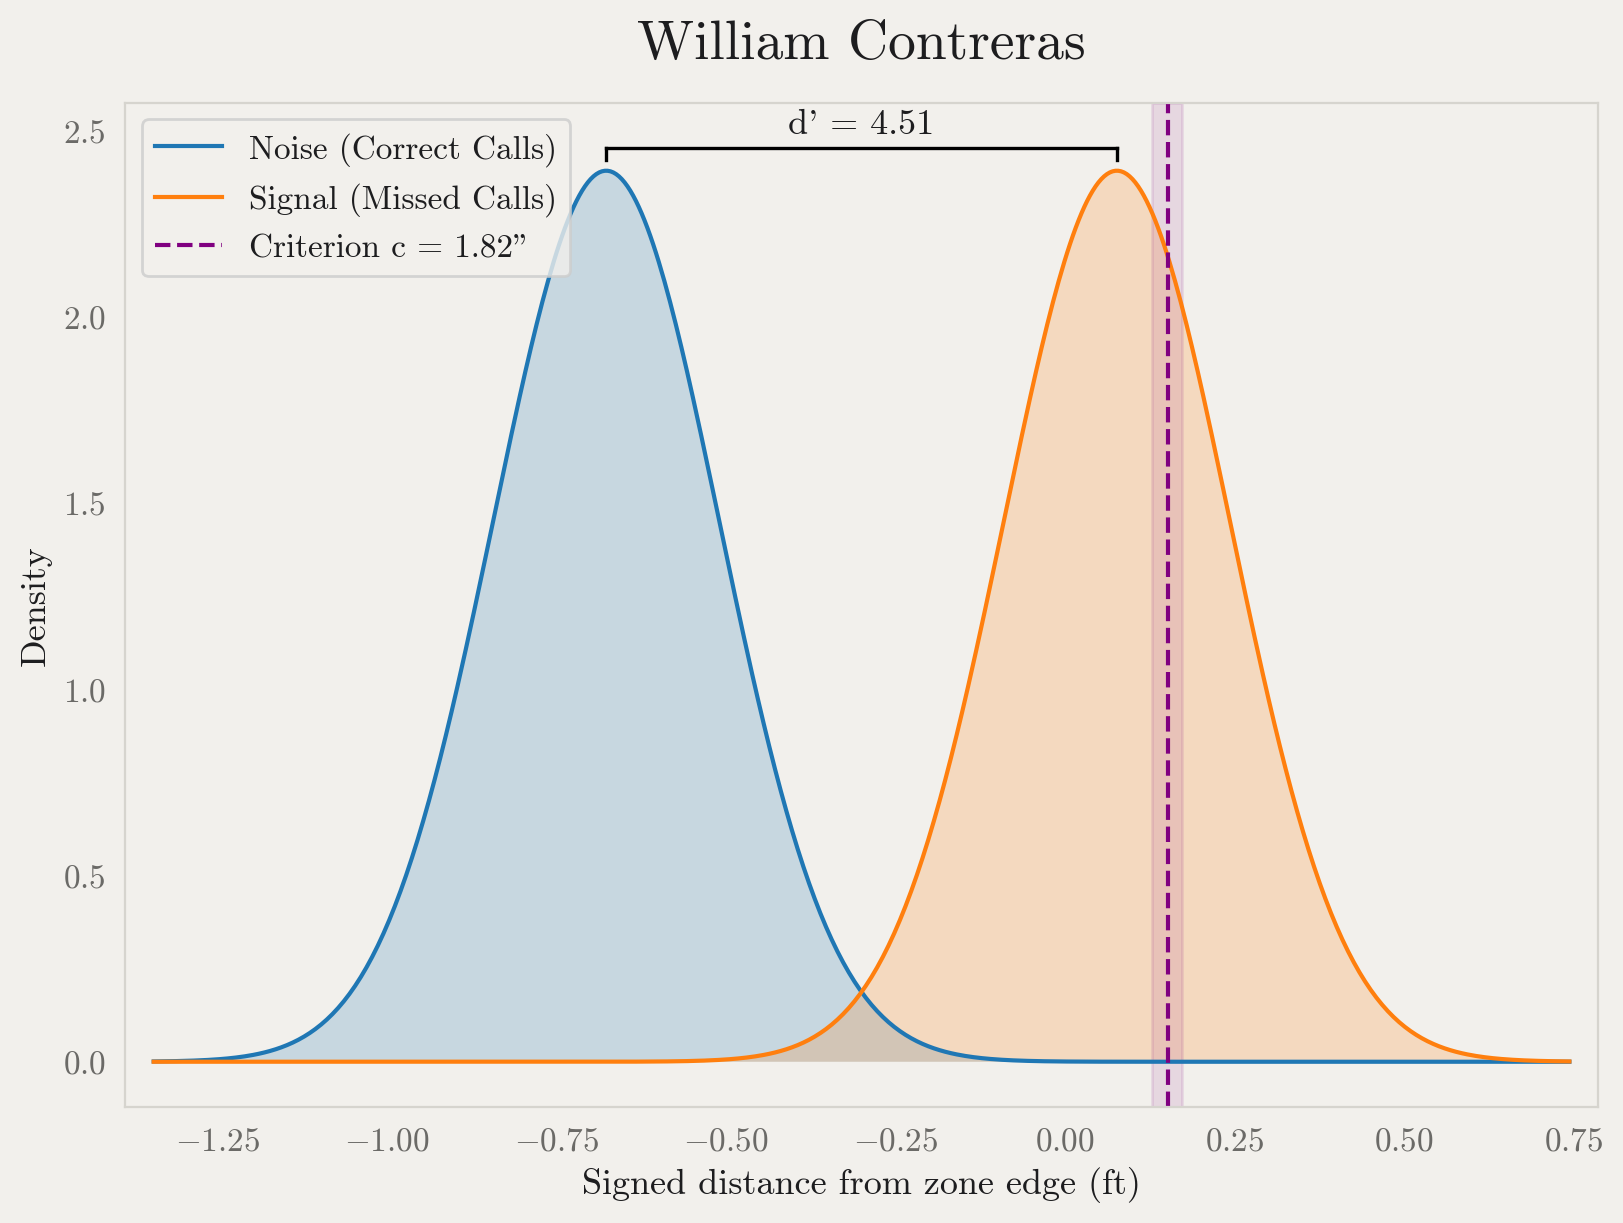

In [60]:
plot_sdt('661388', catcher_summary)

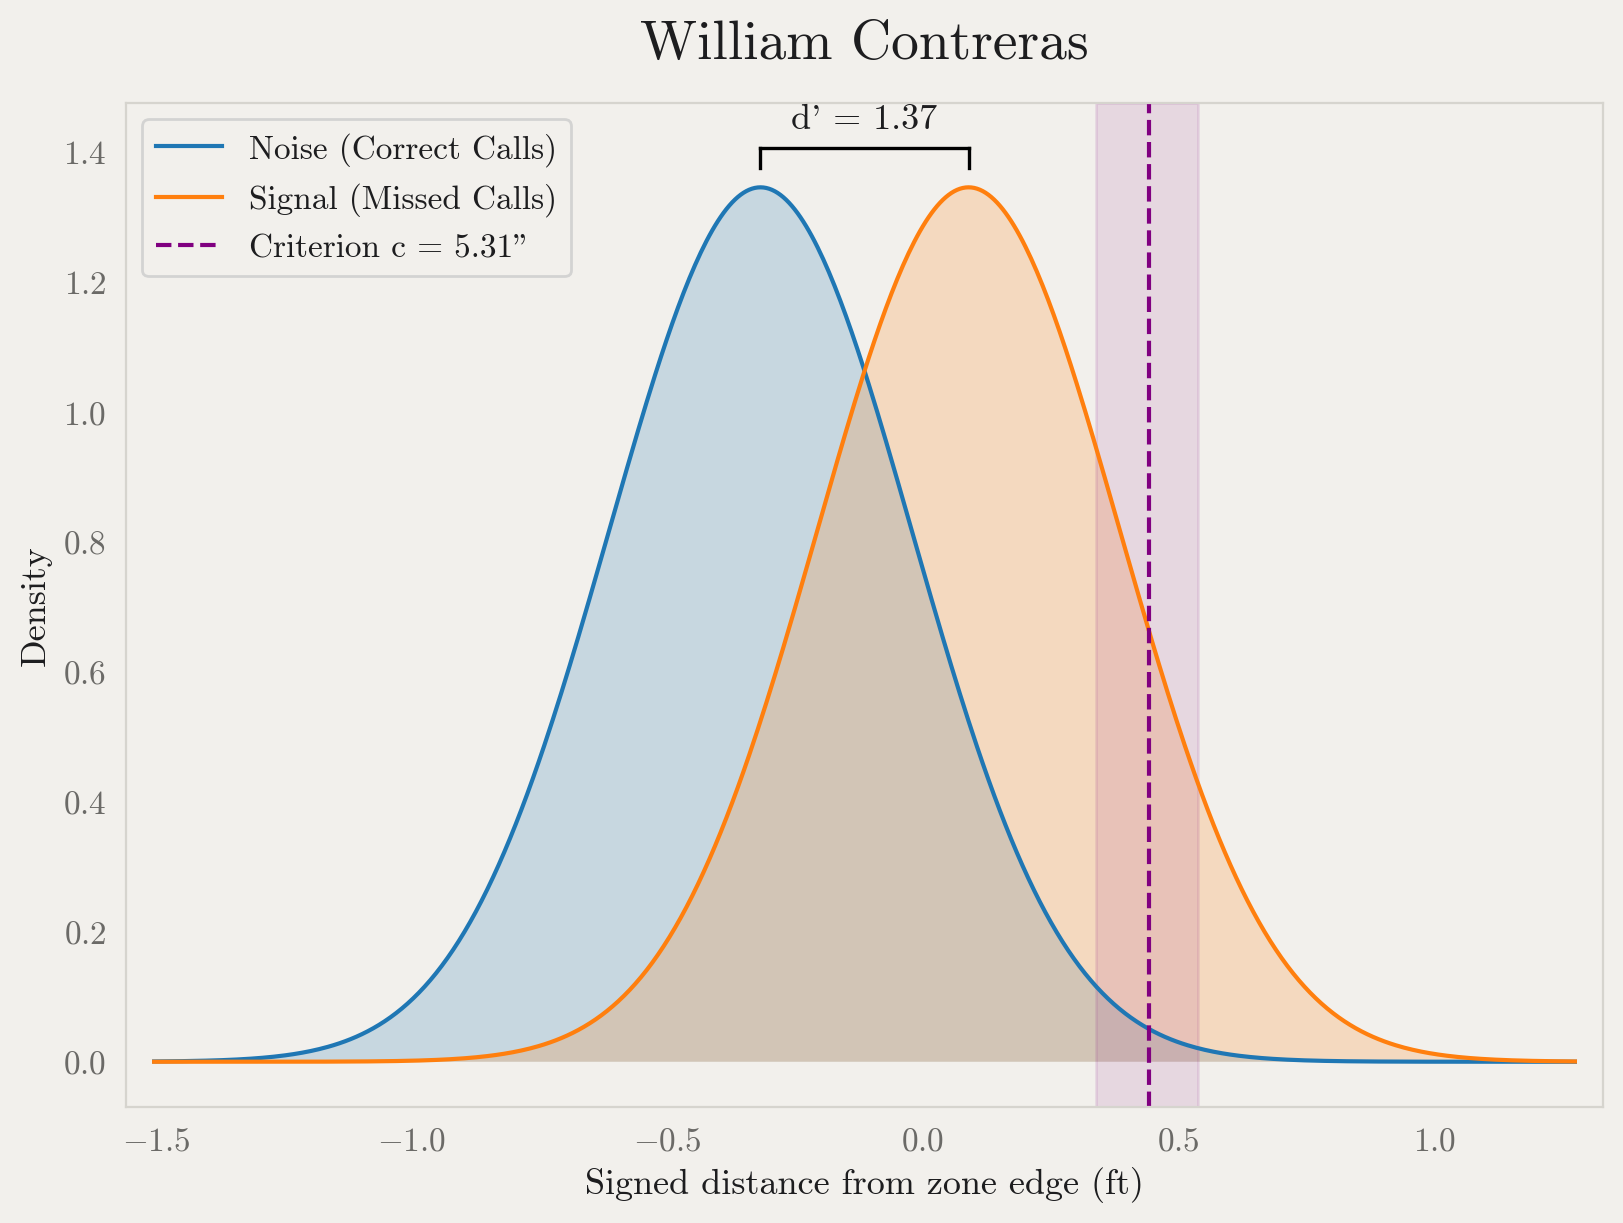

In [61]:
plot_sdt('661388', hitter_summary)

## Conclusions

1. **Perception is nearly uniform; decision criteria are not.** Within both batters and catchers, the player-to-player spread in criterion is two to three times the spread in perceptual noise, measured in the same physical units. Players differ mainly in how much evidence they demand, not in how well they see the zone.
2. **Batters are very conservative.** The typical batter's 50% challenge point is 4.7 in outside the zone, while the median missed call is 0.8 in outside. As a result, 82% of missed strike calls go unchallenged.
3. **Catchers are more aggressive and more perceptive**, which explains their higher success rate. They still leave 71% of missed ball calls unchallenged.
4. **Outcome leaderboards mix both dimensions.** The model's criterion ranking recovers most of the recall leaders without seeing challenge outcomes, and shows that precision can come from caution rather than skill.

## Limitations

- **Challenge availability.** About 7% of the modeled pitches came when the player's team had no challenges left. Those pitches are coded as declined challenges even though the player had no choice, which biases c upward (more conservative) for players on teams that ran out often. The fix is to filter on `pre_batting_challenges > 0` / `pre_fielding_challenges > 0` and refit.
- **Fixed criterion.** c doesn't respond to game situation such as count, score or inning. Any situational variation is absorbed into σ, so σ is an upper bound on pure perceptual noise.
- **Gaussian noise and equal variance.** The probit link follows from the Gaussian noise assumption; other noise distributions weren't tested.
- **Pitchers** aren't modeled. A competing-risks model, with pitcher and catcher as two possible challengers on the same pitch, would be the principled way to include them.

## Next steps

- **Expected value of a challenge:** the run-expectancy gain from an overturn on every eligible pitch, challenged or not.
- **Option value:** a held challenge is an option on future missed calls, worth more early in the game. Combined with each player's σ, this gives an economically optimal criterion to compare against the observed one.
- **Situational criterion:** extend the model to c = c_base − λ·EV, to measure how much players adjust their threshold to the stakes.